# SmartFactory: Predictive Quality Control with Classical ML and Neural Networks

**Module:** 6FTC2175 Advanced Machine Learning and Neural Networks — Assignment 1


A manufacturing line produces two kinds of data that can flag a bad unit before it reaches a customer:

1. **Sensor readings** taken during production → *AI4I 2020 Predictive Maintenance* dataset (tabular).
2. **Photographs** of the finished part → *Casting Product Image Data for Quality Inspection* (images).

| Part | Data | Models |
|---|---|---|
| **A** | AI4I 2020 sensor table | Random Forest (classical ensemble) vs. feed-forward MLP |
| **B** | Casting images | CNN trained from scratch, three architecture iterations |
| **C** | Both | Critical comparison and deployment recommendation |

Throughout, the **positive class (label 1) is the bad outcome** (machine failure / defective casting), so *recall* means "share of bad units we catch" and *precision* means "share of alarms that were real".



## 0. Setup

In [ ]:
# Configuration (change here, not further down)
SEED        = 42
IMG_SIZE    = 128      # casting images are 300x300; 128x128 keeps training fast and still shows the defects
BATCH_SIZE  = 32       # CNN batch size
CNN_EPOCHS  = 60       # upper bound and length of the cosine learning-rate schedule
CNN_LR      = 1e-3     # CNN starting learning rate, decayed to ~0 by a cosine schedule
MLP_EPOCHS  = 300      # upper bound; early stopping usually ends sooner
RF_N_TREES  = 300
N_SEEDS     = 5        # repeats for the seed-stability check in Part A
RUN_CNN_DATA_SIZE = True   # Part C training-size experiment for the CNN (~10 extra GPU minutes)
V3_BATCHNORM = False   # True reproduces the first run's v3 with batch norm, whose validation loss was unstable (see B2)
OUT_DIR     = "outputs"
SAVE_TO_DRIVE = False  # True: keep outputs/ and trained models on Google Drive, so a Colab disconnect loses nothing
USE_MODEL_CACHE = True # reuse trained CNNs saved in outputs/models instead of retraining (keyed by all settings)

In [ ]:
import os, time, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, precision_recall_curve)

warnings.filterwarnings("ignore", category=UserWarning)
tf.get_logger().setLevel("ERROR")          # hide harmless retracing warnings
keras.utils.set_random_seed(SEED)          # seeds python, numpy and TensorFlow
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = "/content/drive/MyDrive/SmartFactory_outputs"
os.makedirs(OUT_DIR, exist_ok=True)
MODEL_DIR = os.path.join(OUT_DIR, "models")
os.makedirs(MODEL_DIR, exist_ok=True)

def save_fig(name):
    plt.savefig(f"{OUT_DIR}/{name}.png", dpi=150, bbox_inches="tight")

GPUS = tf.config.list_physical_devices("GPU")
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("GPU:", GPUS if GPUS else "none — running on CPU. Part B will take a few hours instead of ~30 min.")

TensorFlow 2.21.0 | Keras 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# Evaluation helpers shared by all three models
def evaluate(y_true, prob, threshold=0.5):
    # All the metrics we report, at a given decision threshold.
    pred = (prob >= threshold).astype(int)
    return {
        "threshold":    threshold,
        "accuracy":     accuracy_score(y_true, pred),
        "balanced_acc": balanced_accuracy_score(y_true, pred),
        "precision":    precision_score(y_true, pred, zero_division=0),
        "recall":       recall_score(y_true, pred, zero_division=0),
        "f1":           f1_score(y_true, pred, zero_division=0),
        "roc_auc":      roc_auc_score(y_true, prob),
        "pr_auc":       average_precision_score(y_true, prob),
    }

def best_f1_threshold(y_true, prob):
    # Threshold that maximises F1 — chosen on VALIDATION data only, never on test.
    p, r, t = precision_recall_curve(y_true, prob)
    f1 = 2 * p * r / (p + r + 1e-12)
    return float(t[np.argmax(f1[:-1])])

---
# Part A — Classical vs. feed-forward models on sensor data

## A1. Load the AI4I 2020 dataset

AI4I 2020 (Matzka, 2020a; 2020b) contains 10,000 production records. Each row has the product quality variant (`Type`: L/M/H), air and process temperature, spindle speed, torque and tool wear, plus a binary `Machine failure` label.

**Why this dataset instead of SECOM:** AI4I's features are physically meaningful (temperature, torque, speed, wear), which makes interpretability a real part of the comparison in Part C. SECOM's 590 anonymised sensor columns can't be explained in plant terms. Note that despite the brief describing AI4I as "more balanced", it is actually *more* imbalanced than SECOM (≈3.4% vs ≈6.6% failures), so imbalance is handled explicitly below.

**Caveat that shapes the whole analysis:** AI4I is a *synthetic* dataset, generated to mirror a real milling process. Its failures are produced by documented rules (e.g. heat-dissipation failure when the air–process temperature gap is below 8.6 K *and* speed is below 1380 rpm), plus a small share of purely random failures. Rule-generated labels favour models that learn threshold rules, and results on synthetic data may overstate what is achievable on a real line. This is revisited in the limitations (C6).

**How this maps to the SmartFactory brief:** AI4I labels a *machine* failure during the production of a unit rather than a unit failing final QC. A failure while a unit is being made is a strong signal that the unit itself is at risk, so predicting it is a reasonable stand-in for "will this unit fail quality control", and it lets the line react *before* the unit is finished. This framing is a limitation as well as a strength, and is discussed in C6.

In [ ]:
# Official source first (UCI); a public GitHub copy of the same CSV is the last-resort fallback.
AI4I_URL    = "https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip"
AI4I_MIRROR = ("https://raw.githubusercontent.com/lingchenlijing/AI4I-2020-Predictive-Maintenance-Dataset/"
               "master/data/ai4i2020.csv")
raw = None
try:
    raw = pd.read_csv(AI4I_URL)
    print("Loaded from UCI.")
except Exception as e:
    print("UCI download failed:", type(e).__name__)
if raw is None:
    try:
        import subprocess, sys
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ucimlrepo"], check=True)
        from ucimlrepo import fetch_ucirepo
        raw = fetch_ucirepo(id=601).data.original
        print("Loaded via ucimlrepo.")
    except Exception as e:
        print("ucimlrepo failed:", type(e).__name__)
if raw is None:
    raw = pd.read_csv(AI4I_MIRROR, encoding="utf-8-sig")
    print("Loaded from the GitHub mirror of the UCI file.")
assert raw.shape == (10000, 14) and int(raw["Machine failure"].sum()) == 339, "unexpected AI4I file"

print(raw.shape)
raw.head()

Loaded from UCI.
(10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [ ]:
# Shorter column names
df = raw.rename(columns={
    "Air temperature [K]":     "air_temp_K",
    "Process temperature [K]": "process_temp_K",
    "Rotational speed [rpm]":  "speed_rpm",
    "Torque [Nm]":             "torque_Nm",
    "Tool wear [min]":         "tool_wear_min",
    "Machine failure":         "failure",
}).copy()

FAILURE_MODES = ["TWF", "HDF", "PWF", "OSF", "RNF"]   # tool wear, heat dissipation, power, overstrain, random
NUM_RAW = ["air_temp_K", "process_temp_K", "speed_rpm", "torque_Nm", "tool_wear_min"]
CAT     = ["Type"]

df.info()
df[NUM_RAW].describe().round(2)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   UDI             10000 non-null  int64  
 1   Product ID      10000 non-null  object 
 2   Type            10000 non-null  object 
 3   air_temp_K      10000 non-null  float64
 4   process_temp_K  10000 non-null  float64
 5   speed_rpm       10000 non-null  int64  
 6   torque_Nm       10000 non-null  float64
 7   tool_wear_min   10000 non-null  int64  
 8   failure         10000 non-null  int64  
 9   TWF             10000 non-null  int64  
 10  HDF             10000 non-null  int64  
 11  PWF             10000 non-null  int64  
 12  OSF             10000 non-null  int64  
 13  RNF             10000 non-null  int64  
dtypes: float64(3), int64(9), object(2)
memory usage: 1.1+ MB


,air_temp_K,process_temp_K,speed_rpm,torque_Nm,tool_wear_min
count,10000.0,10000.00,10000.00,10000.00,10000.00
mean,300.0,310.01,1538.78,39.99,107.95
std,2.0,1.48,179.28,9.97,63.65
min,295.3,305.70,1168.00,3.80,0.00
25%,298.3,308.80,1423.00,33.20,53.00
50%,300.1,310.10,1503.00,40.10,108.00
75%,301.5,311.10,1612.00,46.80,162.00
max,304.5,313.80,2886.00,76.60,253.00


## A2. Exploratory analysis

In [ ]:
n_fail = int(df["failure"].sum())
print(f"Failures: {n_fail} of {len(df)}  ({n_fail/len(df):.2%})")
print(f"A model that always predicts 'pass' would score {1 - n_fail/len(df):.2%} accuracy — so accuracy alone is useless here.\n")

print("Failure-mode counts:")
print(df[FAILURE_MODES].sum().to_string())
any_mode = df[FAILURE_MODES].any(axis=1)
print("\nFailure label vs. 'any failure mode flagged':")
print(pd.crosstab(df["failure"], any_mode, rownames=["failure"], colnames=["any mode"]))

Failures: 339 of 10000  (3.39%)
A model that always predicts 'pass' would score 96.61% accuracy — so accuracy alone is useless here.

Failure-mode counts:
TWF     46
HDF    115
PWF     95
OSF     98
RNF     19

Failure label vs. 'any failure mode flagged':
any mode  False  True 
failure               
0          9643     18
1             9    330


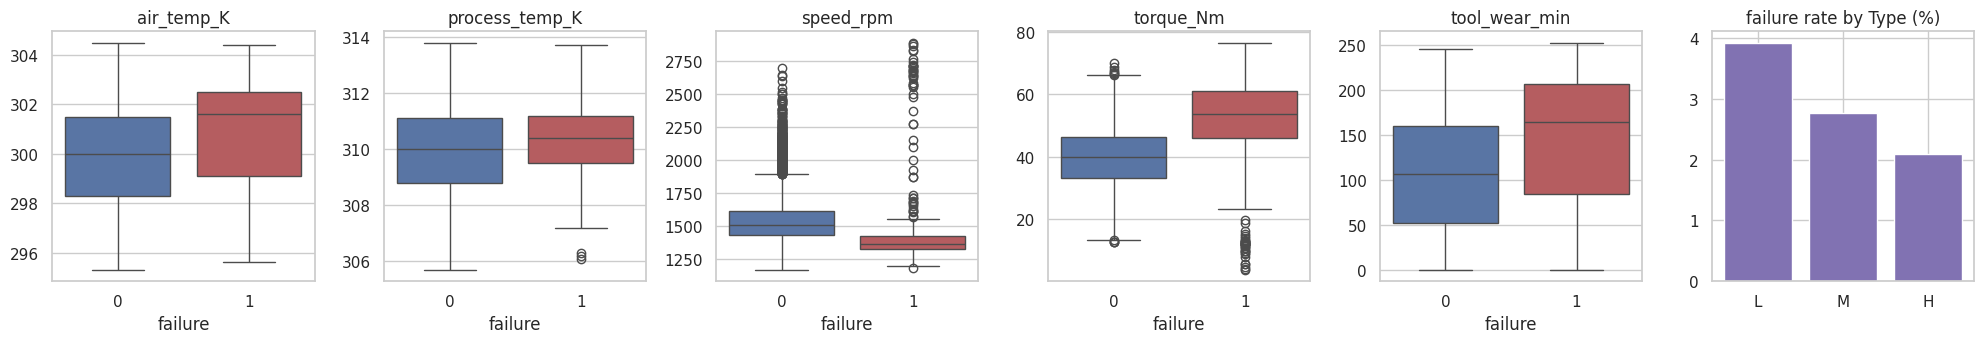

In [ ]:
fig, axes = plt.subplots(1, 6, figsize=(20, 3.6))
for ax, col in zip(axes, NUM_RAW):
    sns.boxplot(data=df, x="failure", y=col, ax=ax, hue="failure", palette=["#4C72B0", "#C44E52"], legend=False)
    ax.set_title(col); ax.set_xlabel("failure"); ax.set_ylabel("")
rate = df.groupby("Type")["failure"].mean().reindex(["L", "M", "H"]) * 100
axes[-1].bar(rate.index, rate.values, color="#8172B2")
axes[-1].set_title("failure rate by Type (%)")
plt.tight_layout(); save_fig("A_eda_boxplots"); plt.show()

**What the EDA shows**

- **Severe class imbalance** (≈3.4% failures). We therefore use stratified splits, test class weighting (A4, A5), tune decision thresholds on validation data, and report **recall, precision, F1 and PR-AUC** rather than accuracy. PR-AUC is the headline metric because it focuses on the rare positive class.
- **Failures are shifted towards high torque, low speed and high tool wear** (median torque ≈54 Nm for failures vs ≈40 Nm for passes), and failure rate falls with product quality (L ≈3.9% → M ≈2.8% → H ≈2.1%). The pattern is also **two-sided**: a cluster of failures sits at very *high* speed and very *low* torque, the opposite end from the main group. That matches the power-failure mechanism (power too low *or* too high). A two-sided rule cannot be drawn by a single straight-line boundary, which favours non-linear models. Tree ensembles express such rules directly, while an MLP has to learn them from relatively few positives.
- The five failure-mode flags (`TWF`…`RNF`) are recorded *after* the failure and essentially define the label, so **they must be dropped** to avoid target leakage. The crosstab also shows the label is slightly noisy (some failures have no mode flagged and vice versa — mostly the random `RNF` mode), which caps achievable performance.

## A3. Feature engineering, leakage removal and splitting

The dataset documentation describes the failure mechanisms in physical terms, so three engineered features are added:

| Feature | Formula | Physical meaning |
|---|---|---|
| `temp_diff_K` | process − air temperature | heat-dissipation failures happen when this gap is small |
| `power_W` | torque × speed × 2π / 60 | power failures happen when power is too low or too high |
| `strain` | tool wear × torque | overstrain failures depend on this product |

These are legitimate (computed only from inputs, no label information) and an ablation in A4 measures how much they help.

**Split:** 64% train / 16% validation / 20% test, all **stratified** on the label. The validation set is used for early stopping and threshold selection; the **test set is touched once**, at the end, for both models.

In [ ]:
df["temp_diff_K"] = df["process_temp_K"] - df["air_temp_K"]
df["power_W"]     = df["torque_Nm"] * df["speed_rpm"] * 2 * np.pi / 60
df["strain"]      = df["tool_wear_min"] * df["torque_Nm"]
NUM_ENG = ["temp_diff_K", "power_W", "strain"]

DROP = ["UDI", "Product ID"] + FAILURE_MODES        # identifiers + leakage columns
X = df.drop(columns=DROP + ["failure"])
y = df["failure"].astype(int)

X_trval, X_test, y_trval, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val   = train_test_split(X_trval, y_trval, test_size=0.20, stratify=y_trval, random_state=SEED)

pd.DataFrame({
    "rows":     [len(y_train), len(y_val), len(y_test)],
    "failures": [y_train.sum(), y_val.sum(), y_test.sum()],
    "rate %":   [round(100 * s.mean(), 2) for s in (y_train, y_val, y_test)],
}, index=["train", "validation", "test"])

,rows,failures,rate %
train,6400,217,3.39
validation,1600,54,3.38
test,2000,68,3.40


In [ ]:
def make_preprocessor(num_cols):
    # Scale numeric columns, one-hot encode Type. Fitted on TRAIN only.
    return ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT),
    ])

FEATURES = NUM_RAW + NUM_ENG
pre = make_preprocessor(FEATURES).fit(X_train[FEATURES + CAT])
Xtr, Xva, Xte = (pre.transform(d[FEATURES + CAT]) for d in (X_train, X_val, X_test))
feature_names = [n.split("__", 1)[1] for n in pre.get_feature_names_out()]
print("Model input:", Xtr.shape[1], "features →", feature_names)

Model input: 11 features → ['air_temp_K', 'process_temp_K', 'speed_rpm', 'torque_Nm', 'tool_wear_min', 'temp_diff_K', 'power_W', 'strain', 'Type_H', 'Type_L', 'Type_M']


## A4. Model 1 — Random Forest (classical ensemble)

**Why a Random Forest for this data**

- **Matches the structure of the problem.** Failures are triggered by thresholds and interactions (e.g. small temperature gap *and* low speed). Decision trees split on exactly these kinds of rules.
- **Bagging reduces variance.** Each tree is trained on a bootstrap sample with a random subset of features; averaging many decorrelated trees gives a stable model even though only ~220 failures are available for training (Lesson 1).
- **Low preprocessing burden and built-in interpretability** — scale-invariant, handles the categorical `Type` easily, and gives feature importances.
- **Imbalance:** `class_weight="balanced_subsample"` re-weights the rare class inside every bootstrap sample; whether this helps is left to the grid search.
- **Why bagging rather than boosting:** some AI4I labels are noisy (random `RNF` failures, and failures with no recorded cause — see the crosstab in A2). Boosting re-weights the examples it gets wrong, so it tends to chase these noisy labels; bagging averages them away. Boosting is also more sensitive to its learning rate / number of rounds.

**Trade-offs accepted:** an RF gives step-shaped (axis-aligned) decision boundaries rather than smooth ones, is larger to store than a small MLP (thousands of tree nodes), and its probabilities are not well calibrated — which is why the threshold is tuned on validation data later.

### Evidence for the choice: screening every classical option in the brief

Before tuning, each classical model family allowed by the brief is scored with the same 5-fold stratified CV on the training set (default settings, class weighting where supported). This checks the argument above against data rather than relying on it.

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
candidates = {
    "Random Forest (bagging)":   RandomForestClassifier(n_estimators=RF_N_TREES, class_weight="balanced_subsample",
                                                        random_state=SEED, n_jobs=-1),
    "Gradient Boosting":         GradientBoostingClassifier(random_state=SEED),
    "AdaBoost":                  AdaBoostClassifier(random_state=SEED),
    "SVM (RBF kernel)":          SVC(kernel="rbf", class_weight="balanced", random_state=SEED),
    "Gaussian Naive Bayes":      GaussianNB(),
}
screen = {}
for name, model in candidates.items():
    res = cross_validate(model, Xtr, y_train, cv=cv, scoring=["average_precision", "roc_auc", "f1"], n_jobs=-1)
    screen[name] = {"CV PR-AUC": res["test_average_precision"].mean(), "± std": res["test_average_precision"].std(),
                    "CV ROC-AUC": res["test_roc_auc"].mean(), "CV F1 @0.5": res["test_f1"].mean(),
                    "fit time (s)": res["fit_time"].mean()}
screen = pd.DataFrame(screen).T.sort_values("CV PR-AUC", ascending=False).round(3)
screen.to_csv(f"{OUT_DIR}/A_classical_screen.csv")
screen

,CV PR-AUC,± std,CV ROC-AUC,CV F1 @0.5,fit time (s)
Gradient Boosting,0.913,0.046,0.980,0.881,1.619
Random Forest (bagging),0.893,0.046,0.978,0.846,3.442
AdaBoost,0.747,0.061,0.970,0.559,0.436
SVM (RBF kernel),0.684,0.067,0.956,0.474,0.329
Gaussian Naive Bayes,0.472,0.094,0.911,0.476,0.004


**Reading the screen.** Naïve Bayes assumes features are independent given the class, which is clearly violated (process temperature tracks air temperature; power is built from torque and speed), so it is expected to trail. The SVM can model non-linear boundaries through the RBF kernel but has no feature importances and scales poorly with data size. The Random Forest is selected because it is at or near the top of the screen *and* gives the interpretability and noise-robustness argued above.

**Result.** Gradient boosting ranked first (CV PR-AUC 0.913 ± 0.046) and the Random Forest second (0.893 ± 0.046). The gap of 0.020 is less than half a standard deviation across folds, so the two are not distinguishable on this data, and after tuning (below) the RF reaches 0.908, within 0.005 of untuned boosting. The other families trail clearly: AdaBoost 0.747, SVM 0.684, Naïve Bayes 0.472.

Two details support the reasoning above. AdaBoost falls far behind gradient boosting, which fits the label-noise argument: it re-weights misclassified points exponentially, so the random failures and the 9 failures with no recorded cause attract the most weight. Naïve Bayes has a respectable ROC-AUC (0.911) but the worst PR-AUC, a reminder that ROC-AUC flatters models when the positive class is rare. The Random Forest is kept: statistically tied for best, more robust to noisy labels, fewer sensitive hyperparameters, and directly interpretable.

### Tuning the Random Forest

Hyperparameters are tuned with **5-fold stratified cross-validation on the training set**, scoring on **average precision (PR-AUC)**.

In [ ]:
param_grid = {
    "max_depth":        [None, 12],
    "min_samples_leaf": [1, 3, 5],
    "max_features":     ["sqrt", 0.5],
    "class_weight":     [None, "balanced_subsample"],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
grid = GridSearchCV(RandomForestClassifier(n_estimators=RF_N_TREES, random_state=SEED, n_jobs=-1),
                    param_grid, scoring="average_precision", cv=cv, n_jobs=-1)

t0 = time.perf_counter()
grid.fit(Xtr, y_train)
rf_search_time = time.perf_counter() - t0
rf = grid.best_estimator_
rf_fit_time = grid.refit_time_            # time for ONE final fit with the best settings

print(f"Grid search: {len(grid.cv_results_['params'])} settings x 5 folds in {rf_search_time:.1f}s")
print(f"Single final fit: {rf_fit_time:.2f}s")
print("Best params:", grid.best_params_)
print(f"Best CV PR-AUC: {grid.best_score_:.3f}")

(pd.DataFrame(grid.cv_results_)
   .assign(param_class_weight=lambda d: d["param_class_weight"].map(lambda v: "None" if pd.isna(v) else str(v)),
           param_max_depth=lambda d: d["param_max_depth"].map(lambda v: "None" if pd.isna(v) else str(int(v))))
   .sort_values("rank_test_score")
   [["param_max_depth", "param_min_samples_leaf", "param_max_features", "param_class_weight",
     "mean_test_score", "std_test_score"]]
   .head(6).round(3))

Grid search: 24 settings x 5 folds in 263.9s
Single final fit: 3.18s
Best params: {'class_weight': None, 'max_depth': 12, 'max_features': 0.5, 'min_samples_leaf': 1}
Best CV PR-AUC: 0.908


,param_max_depth,param_min_samples_leaf,param_max_features,param_class_weight,mean_test_score,std_test_score
9,12,1,0.5,None,0.908,0.043
4,None,3,0.5,None,0.908,0.042
10,12,3,0.5,None,0.907,0.042
5,None,5,0.5,None,0.907,0.044
3,None,1,0.5,None,0.906,0.045
11,12,5,0.5,None,0.905,0.045


**Ablation — do the engineered features matter?** Same best Random Forest settings, trained on raw features only vs. raw + engineered, scored on the validation set.

In [ ]:
pre_raw = make_preprocessor(NUM_RAW).fit(X_train[NUM_RAW + CAT])
rf_raw = RandomForestClassifier(n_estimators=RF_N_TREES, random_state=SEED, n_jobs=-1, **grid.best_params_)
rf_raw.fit(pre_raw.transform(X_train[NUM_RAW + CAT]), y_train)

ablation = pd.DataFrame({
    "raw features only":   evaluate(y_val, rf_raw.predict_proba(pre_raw.transform(X_val[NUM_RAW + CAT]))[:, 1]),
    "raw + engineered":    evaluate(y_val, rf.predict_proba(Xva)[:, 1]),
}).T[["pr_auc", "roc_auc", "f1", "recall", "precision"]].round(3)
ablation.to_csv(f"{OUT_DIR}/A_feature_ablation.csv")
ablation

,pr_auc,roc_auc,f1,recall,precision
raw features only,0.801,0.970,0.733,0.611,0.917
raw + engineered,0.880,0.975,0.875,0.778,1.000


**Capacity of the Random Forest.** Over- and underfitting are not only a neural-network issue. A tree's `max_depth` controls its capacity: shallow trees cannot represent the failure rules (underfitting), while unlimited depth lets each tree memorise its bootstrap sample. The validation curve below varies depth with the other tuned settings fixed, and compares training and cross-validated PR-AUC.

Bagging is what makes deep trees safe: each tree overfits *differently*, and averaging cancels much of that variance. So the train–CV gap is expected to widen with depth while the CV score levels off, rather than falling sharply as it would for a single deep tree.

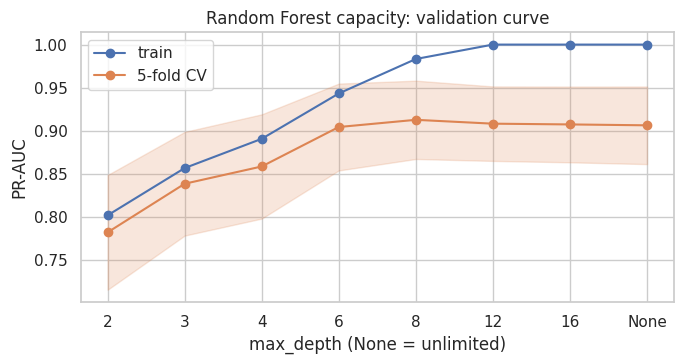

,train PR-AUC,CV PR-AUC,CV std,gap (train − CV)
max_depth,,,,
2,0.802,0.782,0.067,0.020
3,0.857,0.838,0.060,0.018
4,0.891,0.858,0.061,0.032
6,0.943,0.904,0.050,0.039
8,0.983,0.913,0.045,0.071
12,1.000,0.908,0.043,0.092
16,1.000,0.907,0.044,0.093
None,1.000,0.906,0.045,0.094


In [ ]:
from sklearn.model_selection import validation_curve

depths = [2, 3, 4, 6, 8, 12, 16, None]
other = {k: v for k, v in grid.best_params_.items() if k != "max_depth"}
train_sc, cv_sc = validation_curve(
    RandomForestClassifier(n_estimators=RF_N_TREES, random_state=SEED, n_jobs=-1, **other),
    Xtr, y_train, param_name="max_depth", param_range=depths,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED), scoring="average_precision", n_jobs=-1)

labels = [str(d) for d in depths]
rf_capacity = pd.DataFrame({"train PR-AUC": train_sc.mean(1), "CV PR-AUC": cv_sc.mean(1),
                            "CV std": cv_sc.std(1)}, index=pd.Index(labels, name="max_depth"))
rf_capacity["gap (train − CV)"] = rf_capacity["train PR-AUC"] - rf_capacity["CV PR-AUC"]
rf_capacity.round(3).to_csv(f"{OUT_DIR}/A_rf_capacity.csv")

plt.figure(figsize=(7, 3.8))
x = np.arange(len(labels))
plt.plot(x, rf_capacity["train PR-AUC"], "o-", label="train")
plt.plot(x, rf_capacity["CV PR-AUC"], "o-", label="5-fold CV")
plt.fill_between(x, cv_sc.mean(1) - cv_sc.std(1), cv_sc.mean(1) + cv_sc.std(1), alpha=0.2, color="C1")
plt.xticks(x, labels); plt.xlabel("max_depth (None = unlimited)"); plt.ylabel("PR-AUC")
plt.title("Random Forest capacity: validation curve"); plt.legend()
plt.tight_layout(); save_fig("A_rf_validation_curve"); plt.show()
rf_capacity.round(3)

**Result.** Cross-validated PR-AUC climbs from 0.782 at depth 2 to 0.913 at depth 8. Shallow trees **underfit** because the failure rules need several splits: a heat-dissipation failure needs a temperature-gap split *and* a speed split. Beyond depth 8 the CV score is flat (0.906–0.908) while training PR-AUC reaches 1.000 by depth 12, so the train − CV gap widens from 0.020 to 0.094. Each tree memorises its bootstrap sample, yet the forest's CV score barely moves. That is bagging averaging the variance away, as Lesson 1 predicts, so the large gap does not translate into worse generalisation.

The tuned depth (12) sits on the plateau. Depth 8 scores 0.005 higher, well inside one CV standard deviation (≈0.045), so the difference is noise. Note also that every top grid setting uses `class_weight=None`: re-weighting the failures did not improve the RF's ranking of failures. The MLP shows the same effect in A5.

## A5. Model 2 — Feed-forward neural network (MLP)

**Design choices** (following Lessons 3–4):

- **Small network as the starting design: 11 → 32 → 16 → 1.** With ~6,400 training rows and only ~220 positives, a large network can memorise the failures. Two narrow hidden layers give enough capacity for non-linear boundaries. This is tested against smaller and larger alternatives below rather than assumed.
- **ReLU** hidden activations (avoid vanishing gradients), **sigmoid** output to give P(failure).
- **Binary cross-entropy loss** — the correct loss for a single-output binary classifier with a sigmoid; it is the negative log-likelihood of a Bernoulli output and heavily penalises confident mistakes.
- **Dropout 0.2** after each hidden layer as a regulariser.
- **Class weights** (`balanced`): each failure gets weight ≈14.75 and each pass ≈0.52, so the two classes contribute equally to the loss. The hypothesis is that, without this, the network reaches a low loss by predicting "pass" for almost everything. This is tested below rather than assumed, because class weighting also has a cost: every one of the ~217 training failures is amplified ~15×, so noisy or unpredictable failures pull the decision boundary around.
- **Adam (lr = 0.001), batch size 64**, trained by backpropagation with **early stopping** on validation PR-AUC (patience 30), restoring the best weights.
- Inputs are standardised (done in A3) — essential for gradient-based training, unlike the Random Forest.

**Trade-offs accepted:** an MLP gives smooth decision boundaries and is tiny (under 1,000 weights), but it needs scaling, class weighting and early stopping to work at all on this data, it has more hyperparameters than the RF, and its weights have no physical meaning.

### Iterating on the MLP

Five variants are trained identically and compared on **validation** PR-AUC, to test the capacity and imbalance choices above. The design choices above are *hypotheses*; these runs test them, and the final MLP is whichever wins on validation.

| Variant | Hidden layers | Dropout | Class weights | Tests… |
|---|---|---|---|---|
| perceptron | none (inputs → sigmoid) | – | yes | is a linear boundary enough? (Lesson 3 single-layer perceptron) |
| tiny | 8 | – | yes | too little capacity → underfitting? |
| small (proposed) | 32 → 16 | 0.2 | yes | the proposed design |
| large | 128 → 64 → 32 | – | yes | too much capacity → overfitting? |
| small, unweighted | 32 → 16 | 0.2 | **no** | does class weighting matter? |

In [ ]:
def build_mlp(n_inputs, hidden=(32, 16), dropout=0.2):
    model = keras.Sequential([keras.Input(shape=(n_inputs,))], name="mlp")
    for i, units in enumerate(hidden, start=1):
        model.add(layers.Dense(units, activation="relu", name=f"hidden_{i}"))
        if dropout > 0:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="sigmoid", name="output"))
    return model

class CleanCurves(keras.callbacks.Callback):
    # Keras' own *training* metrics are measured with dropout switched ON and class weights applied, averaged
    # over a whole epoch while the weights change, so they are not comparable with validation metrics.
    # This callback re-scores train AND validation the same way at the end of each epoch:
    # inference mode (dropout off), no class weights, sklearn PR-AUC (average precision) and plain BCE.
    def __init__(self, X_tr, y_tr, X_v, y_v):
        super().__init__()
        self.data = {"train": (X_tr, np.asarray(y_tr)), "val": (X_v, np.asarray(y_v))}
        self.log = {k: [] for k in ["train_ap", "val_ap", "train_bce", "val_bce"]}
        self.overhead = 0.0                      # time spent re-scoring, excluded from the reported fit time
    def on_epoch_end(self, epoch, logs=None):
        t0 = time.perf_counter()
        for name, (X, y) in self.data.items():
            p = np.clip(self.model.predict(X, verbose=0, batch_size=8192).ravel(), 1e-7, 1 - 1e-7)
            self.log[f"{name}_ap"].append(average_precision_score(y, p))
            self.log[f"{name}_bce"].append(float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))))
        self.overhead += time.perf_counter() - t0

def train_mlp(X, y, hidden=(32, 16), dropout=0.2, use_class_weight=True, seed=SEED, X_v=None, y_v=None,
              clean_curves=False):
    # Train one MLP with early stopping on validation PR-AUC. Returns model, history, fit time.
    X_v = Xva if X_v is None else X_v
    y_v = y_val if y_v is None else y_v
    keras.utils.set_random_seed(seed)
    model = build_mlp(X.shape[1], hidden, dropout)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="binary_crossentropy",
                  metrics=[keras.metrics.AUC(curve="PR", name="pr_auc"),
                           keras.metrics.Recall(name="recall"), keras.metrics.Precision(name="precision")])
    cw = None
    if use_class_weight:
        w = compute_class_weight("balanced", classes=np.array([0, 1]), y=np.asarray(y))
        cw = {0: float(w[0]), 1: float(w[1])}
    stop = keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=30, restore_best_weights=True)
    callbacks = [stop]
    if clean_curves:
        curves = CleanCurves(X, y, X_v, y_v)
        callbacks.append(curves)
    t0 = time.perf_counter()
    hist = model.fit(X, np.asarray(y), validation_data=(X_v, np.asarray(y_v)), epochs=MLP_EPOCHS,
                     batch_size=64, class_weight=cw, callbacks=callbacks, verbose=0)
    secs = time.perf_counter() - t0
    history = hist.history
    if clean_curves:
        history = {**history, **curves.log}
        secs -= curves.overhead                  # report pure training time
    return model, history, secs

w = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
print(f"Balanced class weights: pass = {w[0]:.2f}, failure = {w[1]:.2f}")

Balanced class weights: pass = 0.52, failure = 14.75


In [ ]:
MLP_VARIANTS = {
    "perceptron (no hidden)": dict(hidden=(),            dropout=0.0, use_class_weight=True),
    "tiny":                   dict(hidden=(8,),          dropout=0.0, use_class_weight=True),
    "small (proposed)":       dict(hidden=(32, 16),      dropout=0.2, use_class_weight=True),
    "large":                  dict(hidden=(128, 64, 32), dropout=0.0, use_class_weight=True),
    "small, unweighted":      dict(hidden=(32, 16),      dropout=0.2, use_class_weight=False),
}
mlp_runs, rows = {}, {}
for name, cfg in MLP_VARIANTS.items():
    model, h, secs = train_mlp(Xtr, y_train, clean_curves=True, **cfg)
    best = int(np.argmax(h["val_pr_auc"]))                 # the epoch EarlyStopping restored
    mlp_runs[name] = {"model": model, "history": h, "fit_time": secs, "cfg": cfg, "best": best}
    rows[name] = {"parameters": model.count_params(), "epochs run": len(h["loss"]), "best epoch": best + 1,
                  "train PR-AUC": h["train_ap"][best], "val PR-AUC": h["val_ap"][best],
                  "gap (train − val)": h["train_ap"][best] - h["val_ap"][best],
                  "train BCE": h["train_bce"][best], "val BCE": h["val_bce"][best], "fit time (s)": secs}
mlp_table = pd.DataFrame(rows).T.astype(float).round(3)
mlp_table.to_csv(f"{OUT_DIR}/A_mlp_iterations.csv")

MLP_BEST = mlp_table["val PR-AUC"].idxmax()            # selected on validation only
mlp, mlp_hist, mlp_fit_time = (mlp_runs[MLP_BEST][k] for k in ("model", "history", "fit_time"))
MLP_CFG = mlp_runs[MLP_BEST]["cfg"]
print("Selected MLP (best validation PR-AUC):", MLP_BEST)
mlp.summary()
mlp_table

Selected MLP (best validation PR-AUC): small, unweighted


Model: "mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 32)             │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,789 (10.90 KB)

 Trainable params: 929 (3.63 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,860 (7.27 KB)

,parameters,epochs run,best epoch,train PR-AUC,val PR-AUC,gap (train − val),train BCE,val BCE,fit time (s)
perceptron (no hidden),12.0,300.0,299.0,0.467,0.464,0.003,0.377,0.384,130.915
tiny,105.0,300.0,298.0,0.683,0.677,0.007,0.205,0.220,132.158
small (proposed),929.0,81.0,51.0,0.762,0.735,0.026,0.237,0.256,40.116
large,11905.0,90.0,60.0,0.914,0.753,0.161,0.077,0.125,43.039
"small, unweighted",929.0,122.0,92.0,0.864,0.794,0.070,0.043,0.053,56.776


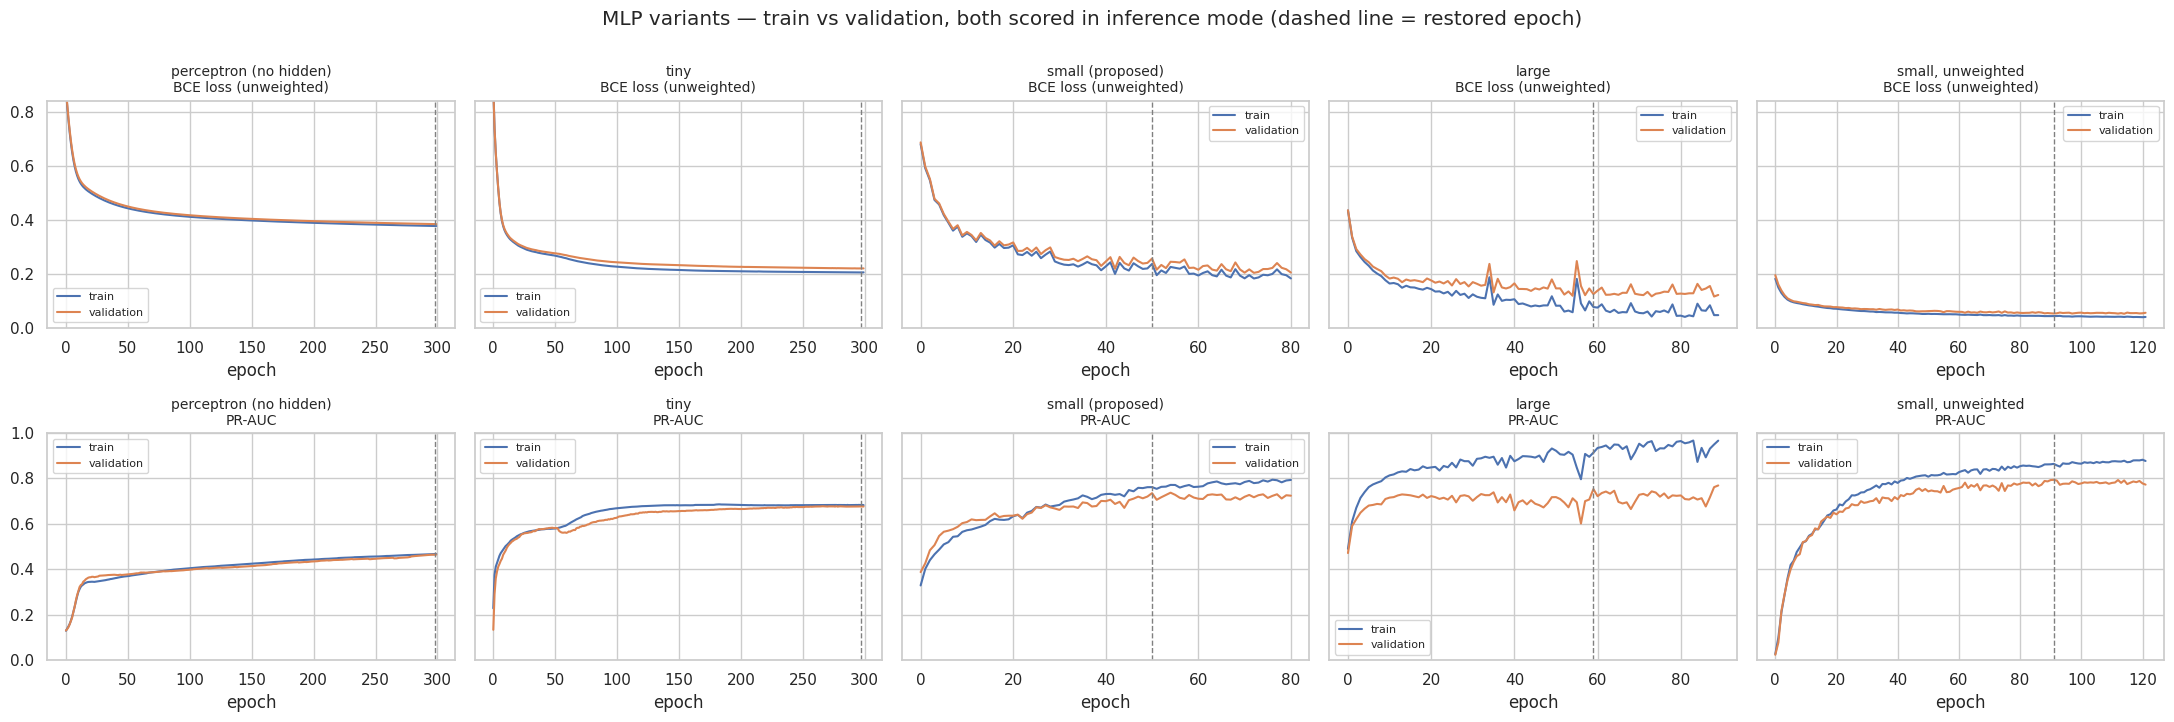

In [ ]:
# All curves measured the same way for train and validation (see CleanCurves), so they are directly comparable.
fig, axes = plt.subplots(2, len(mlp_runs), figsize=(4.4 * len(mlp_runs), 7.2), sharey="row")
for j, (name, r) in enumerate(mlp_runs.items()):
    h, best = r["history"], r["best"]
    axes[0, j].plot(h["train_bce"], label="train"); axes[0, j].plot(h["val_bce"], label="validation")
    axes[0, j].set_title(f"{name}\nBCE loss (unweighted)", fontsize=10)
    axes[1, j].plot(h["train_ap"], label="train"); axes[1, j].plot(h["val_ap"], label="validation")
    axes[1, j].set_title(f"{name}\nPR-AUC", fontsize=10)
    for ax in axes[:, j]:
        ax.axvline(best, ls="--", c="grey", lw=1); ax.set_xlabel("epoch"); ax.legend(fontsize=8)
top = 1.15 * max(max(r["history"]["val_bce"][3:] + r["history"]["train_bce"][3:]) for r in mlp_runs.values())
axes[0, 0].set_ylim(0, top); axes[1, 0].set_ylim(0, 1)      # skip the first epochs so the y-scale isn't squashed
fig.suptitle("MLP variants — train vs validation, both scored in inference mode (dashed line = restored epoch)", y=1.0)
plt.tight_layout(); save_fig("A_mlp_learning_curves"); plt.show()

**How the curves are measured.** Keras' built-in *training* metrics are computed with dropout switched on and class weights applied, and averaged over an epoch while the weights are still changing. On a first run this made validation PR-AUC look *higher* than training PR-AUC for the dropout variants, which is a measurement artefact rather than a real effect. All curves and the table above are therefore re-scored at the end of every epoch on both sets **in the same way** (inference mode, no class weights, plain BCE and PR-AUC), so the train–validation gap is a genuine measure of over/underfitting. Note that class-weighted models output inflated probabilities, so their *unweighted* BCE sits higher even when they rank failures well; PR-AUC is the fairer row for comparing variants. The dashed line marks the epoch whose weights early stopping restored.

- **Underfitting** (tiny): both train and validation PR-AUC plateau low and close together — the network cannot represent the failure rules.
- **Overfitting** (large): train PR-AUC keeps rising while validation PR-AUC stalls or falls, giving the largest train − val gap in the table.
- **Class weighting** (unweighted vs proposed): shows whether re-weighting the rare class changes the *ranking* quality (PR-AUC) or mainly shifts the probabilities, which the tuned threshold then absorbs.

**Result.**

- **Underfitting (perceptron, tiny).** Both use all 300 epochs and end with train and validation PR-AUC almost equal and low: 0.467/0.464 for the perceptron and 0.683/0.677 for the 8-unit network. Small gaps with low scores are the textbook underfitting signature. A single straight-line boundary (perceptron) cannot express the two-sided power rule or the AND-type heat-dissipation rule, and 8 hidden units are still too few. The perceptron's PR-AUC is still creeping up at epoch 300, so it had not fully converged, but at that rate it would remain by far the weakest.
- **Overfitting (large).** With 11,905 weights for 217 training failures, the large network's training PR-AUC climbs to 0.914 while validation stalls at 0.753 and becomes erratic, the largest gap in the table (0.161). Early stopping restored epoch 60 of 90: it is memorising individual failures.
- **Class weighting hurt.** The *unweighted* small network has the best validation PR-AUC (0.794) against 0.735 for the identical weighted network. PR-AUC measures how well failures are *ranked* above passes, which weighting does not improve. What weighting does is multiply each failure's gradient by ~15, which makes training noisier (visible in the jagged "small (proposed)" curves). The imbalance is handled where it actually matters, at the decision threshold chosen on validation data (A6, C4). The Random Forest grid search reached the same conclusion (A4).

**Selected MLP:** small (11 → 32 → 16 → 1, dropout 0.2), **without class weights**, 929 weights, chosen on validation PR-AUC only. Its moderate gap (0.864 train vs 0.794 validation) is the best trade-off between the underfitting small models and the overfitting large one. The original design hypothesis about class weights was wrong, and the experiment exposed that rather than assuming it.

## A6. Test-set comparison

Both models are evaluated on **the same held-out test split**. Each model's decision threshold is chosen on the *validation* set (maximising F1) because on imbalanced data a model's probabilities are not calibrated around 0.5, so the default cut-off is arbitrary. Results at 0.5 are shown too, for transparency. A "always predict pass" baseline shows why accuracy is misleading.

In [ ]:
def mlp_prob(X):
    return mlp.predict(X, verbose=0, batch_size=4096).ravel()

prob = {
    "Random Forest": {"val": rf.predict_proba(Xva)[:, 1], "test": rf.predict_proba(Xte)[:, 1]},
    "MLP":           {"val": mlp_prob(Xva),               "test": mlp_prob(Xte)},
}
thr = {m: best_f1_threshold(y_val, p["val"]) for m, p in prob.items()}

rows = {"Baseline: always 'pass'": evaluate(y_test, np.zeros(len(y_test)))}
for m in prob:
    rows[f"{m} @ 0.5"]   = evaluate(y_test, prob[m]["test"], 0.5)
    rows[f"{m} @ tuned"] = evaluate(y_test, prob[m]["test"], thr[m])
partA = pd.DataFrame(rows).T.round(3)
partA.to_csv(f"{OUT_DIR}/A_test_results.csv")
partA

,threshold,accuracy,balanced_acc,precision,recall,f1,roc_auc,pr_auc
Baseline: always 'pass',0.500,0.966,0.500,0.000,0.000,0.000,0.500,0.034
Random Forest @ 0.5,0.500,0.992,0.897,0.964,0.794,0.871,0.986,0.902
Random Forest @ tuned,0.607,0.991,0.882,0.963,0.765,0.852,0.986,0.902
MLP @ 0.5,0.500,0.980,0.756,0.833,0.515,0.636,0.978,0.768
MLP @ tuned,0.448,0.980,0.770,0.822,0.544,0.655,0.978,0.768


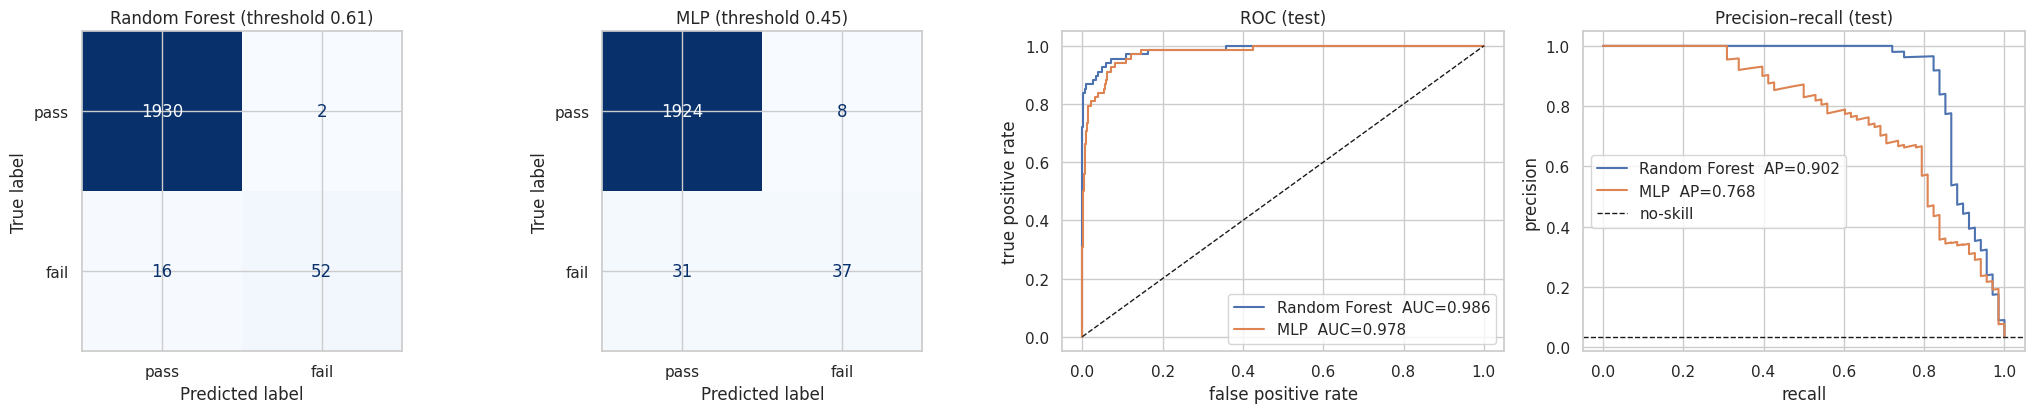

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(21, 4.3))
for ax, m in zip(axes[:2], prob):
    ConfusionMatrixDisplay.from_predictions(y_test, (prob[m]["test"] >= thr[m]).astype(int),
                                            display_labels=["pass", "fail"], cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"{m} (threshold {thr[m]:.2f})")
for m, c in zip(prob, ["#4C72B0", "#DD8452"]):
    fpr, tpr, _ = roc_curve(y_test, prob[m]["test"])
    axes[2].plot(fpr, tpr, c=c, label=f"{m}  AUC={roc_auc_score(y_test, prob[m]['test']):.3f}")
    p, r, _ = precision_recall_curve(y_test, prob[m]["test"])
    axes[3].plot(r, p, c=c, label=f"{m}  AP={average_precision_score(y_test, prob[m]['test']):.3f}")
axes[2].plot([0, 1], [0, 1], "k--", lw=1); axes[2].set(title="ROC (test)", xlabel="false positive rate", ylabel="true positive rate")
axes[3].axhline(y_test.mean(), c="k", ls="--", lw=1, label="no-skill")
axes[3].set(title="Precision–recall (test)", xlabel="recall", ylabel="precision")
axes[2].legend(); axes[3].legend()
plt.tight_layout(); save_fig("A_test_comparison"); plt.show()

**Is the difference real?** The test set has only ~68 failures, so a few misclassified units move F1 noticeably. A bootstrap over the test set (1,000 resamples) gives 95% confidence intervals and a CI for the RF − MLP difference. If the difference interval contains 0, the two models are not distinguishable on this data.

In [ ]:
rng = np.random.default_rng(SEED)
yt = y_test.values
boot = {k: [] for k in ["RF pr_auc", "MLP pr_auc", "RF f1", "MLP f1"]}
for _ in range(1000):
    idx = rng.integers(0, len(yt), len(yt))
    if yt[idx].sum() == 0:
        continue
    for m, short in [("Random Forest", "RF"), ("MLP", "MLP")]:
        pt = prob[m]["test"][idx]
        boot[f"{short} pr_auc"].append(average_precision_score(yt[idx], pt))
        boot[f"{short} f1"].append(f1_score(yt[idx], (pt >= thr[m]).astype(int), zero_division=0))
boot = {k: np.array(v) for k, v in boot.items()}
boot["RF − MLP pr_auc"] = boot["RF pr_auc"] - boot["MLP pr_auc"]
boot["RF − MLP f1"]     = boot["RF f1"] - boot["MLP f1"]

ci = pd.DataFrame({k: {"mean": v.mean(), "2.5%": np.percentile(v, 2.5), "97.5%": np.percentile(v, 97.5)}
                   for k, v in boot.items()}).T.round(3)
ci.to_csv(f"{OUT_DIR}/A_bootstrap_ci.csv")
ci

,mean,2.5%,97.5%
RF pr_auc,0.901,0.835,0.957
MLP pr_auc,0.767,0.661,0.852
RF f1,0.850,0.772,0.917
MLP f1,0.651,0.542,0.748
RF − MLP pr_auc,0.133,0.075,0.205
RF − MLP f1,0.199,0.108,0.293


**Which failures does each model miss?** Breaking test recall down by the recorded failure mechanism shows *where* the models differ. The mode flags are used only for this analysis, never as model inputs. Rule-based mechanisms (heat dissipation, power, overstrain) should be easy to learn from the sensors; tool-wear failures happen at a random wear level between 200 and 240 min and random failures have no sensor signature, so these set a ceiling on achievable recall.

In [ ]:
test_modes = df.loc[X_test.index, FAILURE_MODES]
caught = {m: (prob[m]["test"] >= thr[m]) for m in prob}
groups = {mode: (y_test == 1) & (test_modes[mode] == 1) for mode in FAILURE_MODES}
groups["no mode recorded"] = (y_test == 1) & ~test_modes.any(axis=1)
by_mode = pd.DataFrame({
    g: {"test failures": int(mask.sum()),
        **{f"{m} recall": (caught[m][mask.values].mean() if mask.sum() else np.nan) for m in prob}}
    for g, mask in groups.items()}).T
by_mode.to_csv(f"{OUT_DIR}/A_recall_by_failure_mode.csv")
by_mode.round(2)

,test failures,Random Forest recall,MLP recall
TWF,10.0,0.10,0.10
HDF,29.0,0.86,0.45
PWF,13.0,1.00,0.85
OSF,16.0,0.94,0.88
RNF,0.0,NaN,NaN
no mode recorded,2.0,0.00,0.00


**Is the MLP's result stable?** A single training run can be lucky or unlucky. Both models are retrained with **5 different random seeds** (same data, same settings) and scored on the test set. A model whose score swings a lot between seeds is riskier to deploy and needs more careful retraining.

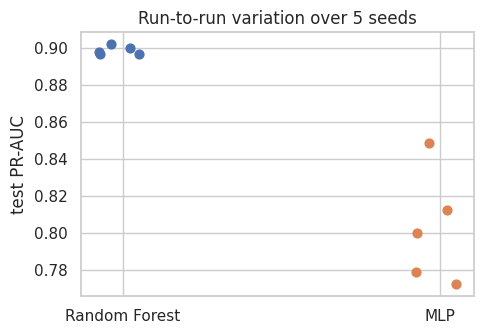

,mean test PR-AUC,std,min,max
Random Forest,0.899,0.002,0.897,0.902
MLP,0.803,0.030,0.773,0.849


In [ ]:
seed_rows = []
for s in range(N_SEEDS):
    rf_s = RandomForestClassifier(n_estimators=RF_N_TREES, random_state=s, n_jobs=-1, **grid.best_params_).fit(Xtr, y_train)
    mlp_s, _, _ = train_mlp(Xtr, y_train, seed=s, **MLP_CFG)
    seed_rows.append({"seed": s,
                      "Random Forest": average_precision_score(y_test, rf_s.predict_proba(Xte)[:, 1]),
                      "MLP": average_precision_score(y_test, mlp_s.predict(Xte, verbose=0).ravel())})
seeds = pd.DataFrame(seed_rows).set_index("seed")
seeds.to_csv(f"{OUT_DIR}/A_seed_stability.csv")
seed_summary = seeds.agg(["mean", "std", "min", "max"]).T.round(3)
seed_summary.columns = ["mean test PR-AUC", "std", "min", "max"]

plt.figure(figsize=(5, 3.5))
for i, m in enumerate(seeds.columns):
    plt.scatter(np.full(len(seeds), i) + np.random.default_rng(0).uniform(-.08, .08, len(seeds)), seeds[m], s=40)
plt.xticks(range(len(seeds.columns)), seeds.columns); plt.ylabel("test PR-AUC")
plt.title(f"Run-to-run variation over {N_SEEDS} seeds")
plt.tight_layout(); save_fig("A_seed_stability"); plt.show()
seed_summary

## A7. What drives each model's predictions?

Two views of feature importance:

- **Impurity importance** (Random Forest only): how much each feature reduces Gini impurity across all splits. Fast but biased towards continuous features.
- **Permutation importance** (both models, model-agnostic): shuffle one input column on the *test* set and measure the drop in PR-AUC. `Type` is permuted as one column. Correlated features (e.g. `power_W` and `torque_Nm`) share credit, so individual values can understate a feature that has a close substitute.

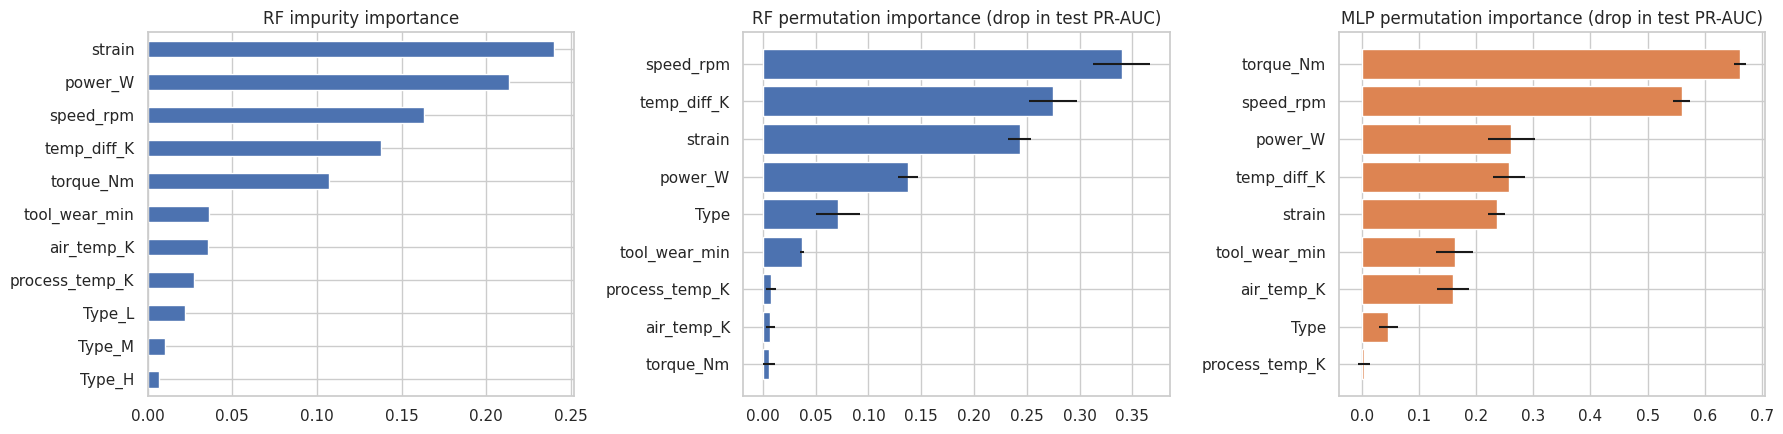

In [ ]:
def permutation_importance_df(prob_fn, X_df, y_true, n_repeats=10, seed=SEED):
    # Model-agnostic permutation importance on raw (pre-pipeline) columns, scored by PR-AUC.
    rng = np.random.default_rng(seed)
    base = average_precision_score(y_true, prob_fn(X_df))
    out = {}
    for col in X_df.columns:
        drops = []
        for _ in range(n_repeats):
            Xp = X_df.copy()
            Xp[col] = rng.permutation(Xp[col].values)
            drops.append(base - average_precision_score(y_true, prob_fn(Xp)))
        out[col] = (np.mean(drops), np.std(drops))
    return pd.DataFrame(out, index=["mean_drop", "std"]).T.sort_values("mean_drop")

X_test_cols = X_test[FEATURES + CAT]
pi_rf  = permutation_importance_df(lambda d: rf.predict_proba(pre.transform(d))[:, 1], X_test_cols, y_test)
pi_mlp = permutation_importance_df(lambda d: mlp_prob(pre.transform(d)), X_test_cols, y_test)
imp_rf = pd.Series(rf.feature_importances_, index=feature_names).sort_values()

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
imp_rf.plot.barh(ax=axes[0], color="#4C72B0"); axes[0].set_title("RF impurity importance")
for ax, pi, name, c in [(axes[1], pi_rf, "RF", "#4C72B0"), (axes[2], pi_mlp, "MLP", "#DD8452")]:
    ax.barh(pi.index, pi["mean_drop"], xerr=pi["std"], color=c)
    ax.set_title(f"{name} permutation importance (drop in test PR-AUC)")
plt.tight_layout(); save_fig("A_feature_importance"); plt.show()

### Part A summary

**The Random Forest clearly outperforms the MLP on the sensor data.** On the held-out test set it scores PR-AUC 0.902 against 0.768, and F1 0.852 against 0.655 (each at its validation-tuned threshold). The bootstrap 95% CI for the difference excludes zero for both PR-AUC (+0.075 to +0.205) and F1 (+0.108 to +0.293). The seed check shows this is not one unlucky MLP run: over 5 seeds the RF barely moves (0.899 ± 0.002) while the MLP varies 15× more (0.803 ± 0.030), and its best seed (0.849) is still below the RF's worst (0.897). In plant terms, the RF catches **52 of the 68** test failures with **2** false alarms; the MLP catches **37** with **8** false alarms.

**Where the gap comes from.** The failure-mode breakdown shows it is mostly heat-dissipation failures (HDF): the RF catches 25 of 29 (86%), the MLP 13 (45%). HDF is an AND-rule (small temperature gap *and* low speed), exactly the axis-aligned conjunction a decision tree encodes in two splits, while the MLP must approximate the corner with smooth ReLU boundaries learned from few examples. The RF also catches all 13 power failures (MLP 11) and 15 of 16 overstrain failures (MLP 14). Both catch only 1 of 10 tool-wear failures. These happen at a *random* wear time between 200 and 240 min, so a single sensor snapshot cannot predict them, and that caps the achievable recall for any model.

One honest wrinkle: for the RF, the validation-tuned threshold (0.61) gave slightly *lower* test F1 than the default 0.5 (0.852 vs 0.871). With only 54 failures in the validation set, the F1-optimal threshold is itself a noisy estimate. This is one more reason C4 sets the operating threshold from costs. The model comparison does not depend on it, because PR-AUC is threshold-free.

**Both models rely on physically sensible drivers**, which makes the results more trustworthy: rotational speed, torque (directly or via power and strain) and the air–process temperature gap. They use them differently. The RF's permutation importance is led by speed, `temp_diff_K` and `strain`, and raw torque scores ≈0 because `power_W` and `strain` already carry its information. The MLP leans most on raw torque and speed. **Feature engineering paid off:** adding the three physics-based features raised the RF's validation PR-AUC from 0.801 to 0.880 and recall from 0.611 to 0.778 (A4).

---
# Part B — Convolutional neural network on product images

## B1. Load the casting image dataset

The *Casting Product Image Data for Quality Inspection* dataset (ravirajsinh45, 2020) contains top-down greyscale photos of submersible pump impellers, labelled `ok_front` or `def_front` (defects such as blow holes, shrinkage, burrs and edge damage). The dataset ships with its own train/test split, which we keep; 20% of the training folder is held out for validation.

Downloaded with `kagglehub` (pre-installed on Colab). If Kaggle is unavailable, the cell falls back to a public GitHub copy of the same files and checks the folder counts match the Kaggle original exactly.

In [ ]:
import shutil, subprocess
try:
    import kagglehub
    path = kagglehub.dataset_download("ravirajsinh45/real-life-industrial-dataset-of-casting-product")
    TRAIN_DIR = os.path.dirname(glob.glob(os.path.join(path, "**", "train", "ok_front"), recursive=True)[0])
    print("Loaded from Kaggle.")
except Exception as e:
    # Fallback: public GitHub copy of the Kaggle files. Its owner moved 64 training images into a separate
    # folder; they are copied back so the layout is identical to the Kaggle original (checked below).
    print("Kaggle download failed:", type(e).__name__, "→ using the GitHub mirror")
    repo, mirror = "https://github.com/peotrannnn/Casting-Quality-Inspection-using-ML-DL.git", "casting_mirror"
    if not os.path.exists(mirror):
        subprocess.run(["git", "clone", "-q", "--depth", "1", "--filter=blob:none", "--sparse", repo, mirror], check=True)
        subprocess.run(["git", "-C", mirror, "sparse-checkout", "set", "--no-cone",
                        "data/raw/casting_data/", "data/leaked_duplicates_removed_from_train/"], check=True)
    TRAIN_DIR = os.path.join(mirror, "data/raw/casting_data/casting_data/train")
    for f in glob.glob(os.path.join(mirror, "data/leaked_duplicates_removed_from_train/ok_front/*")):
        shutil.copy(f, os.path.join(TRAIN_DIR, "ok_front"))
TEST_DIR = os.path.join(os.path.dirname(TRAIN_DIR), "test")
n = {f"{s}/{c}": len(os.listdir(os.path.join(TRAIN_DIR if s == "train" else TEST_DIR, c)))
     for s in ["train", "test"] for c in ["ok_front", "def_front"]}
assert n == {"train/ok_front": 2875, "train/def_front": 3758, "test/ok_front": 262, "test/def_front": 453}, n
print("Folder counts match the Kaggle original:", n)

Using Colab cache for faster access to the 'real-life-industrial-dataset-of-casting-product' dataset.
Loaded from Kaggle.
Folder counts match the Kaggle original: {'train/ok_front': 2875, 'train/def_front': 3758, 'test/ok_front': 262, 'test/def_front': 453}


In [ ]:
CLASS_NAMES = ["ok_front", "def_front"]      # index 0 = OK, index 1 = DEFECT (positive class)
counts = pd.DataFrame({split: {c: len(os.listdir(os.path.join(d, c))) for c in CLASS_NAMES}
                       for split, d in [("train folder", TRAIN_DIR), ("test folder", TEST_DIR)]})
counts.loc["defect %"] = (100 * counts.loc["def_front"] / counts.sum()).round(1)
counts

,train folder,test folder
ok_front,2875.0,262.0
def_front,3758.0,453.0
defect %,56.7,63.4


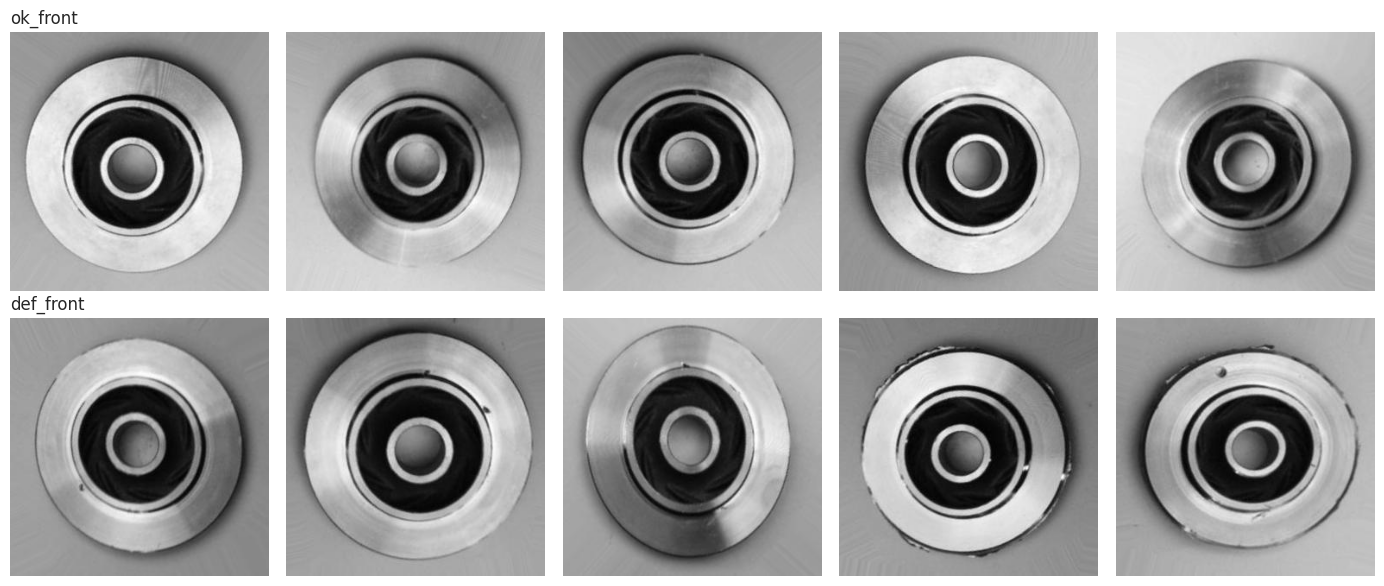

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for row, cls in enumerate(CLASS_NAMES):
    files = sorted(os.listdir(os.path.join(TRAIN_DIR, cls)))[:5]
    for ax, f in zip(axes[row], files):
        ax.imshow(plt.imread(os.path.join(TRAIN_DIR, cls, f)), cmap="gray"); ax.axis("off")
    axes[row, 0].set_title(cls, loc="left", fontsize=12)
plt.tight_layout(); save_fig("B_sample_images"); plt.show()

The classes are only mildly imbalanced (~57% defective in training), and every class has thousands of images, far above the ≥300-per-class guideline, so the full dataset is used and no class weighting is needed. Images are loaded as **single-channel greyscale** at 128×128 (the originals are 300×300 and effectively greyscale), which cuts the input size ~5.5× while keeping defects visible.

### Data-quality check: are any test images also in the training folder?

If the same image appears in both training and test, the test score partly measures memory rather than generalisation (*data leakage*). Every file is fingerprinted (MD5 hash of its bytes) and training files identical to a test file are excluded from training.

In [ ]:
import hashlib
def md5(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

test_hashes = {md5(p) for p in glob.glob(os.path.join(TEST_DIR, "*", "*"))}
CLEAN_TRAIN_DIR = "casting_train_dedup"            # training folder without the leaked images (symlinks, no copies)
shutil.rmtree(CLEAN_TRAIN_DIR, ignore_errors=True)
leaked = {}
for cls in CLASS_NAMES:
    os.makedirs(os.path.join(CLEAN_TRAIN_DIR, cls))
    leaked[cls] = 0
    for p in sorted(glob.glob(os.path.join(TRAIN_DIR, cls, "*"))):
        if md5(p) in test_hashes:
            leaked[cls] += 1
            continue
        os.symlink(os.path.abspath(p), os.path.join(CLEAN_TRAIN_DIR, cls, os.path.basename(p)))
print("Training images identical to a test image (removed):", leaked)
print("Training images kept:", {c: len(os.listdir(os.path.join(CLEAN_TRAIN_DIR, c))) for c in CLASS_NAMES})

Training images identical to a test image (removed): {'ok_front': 64, 'def_front': 0}
Training images kept: {'ok_front': 2811, 'def_front': 3758}


**Result.** 64 `ok_front` training images are byte-for-byte copies of test images (same file names, e.g. `cast_ok_0_937.jpeg` is in both folders). Left in, they would let the CNN be "tested" on pictures it had already trained on. They are removed from training, so the test set stays fully unseen. This flaw in the public dataset is easy to miss. A deeper version of the same problem, rotated and flipped copies of the same part that a file-level check cannot see, is examined in B4 after the models are trained.

In [ ]:
load_kw = dict(image_size=(IMG_SIZE, IMG_SIZE), color_mode="grayscale", label_mode="binary",
               class_names=CLASS_NAMES, batch_size=BATCH_SIZE)
train_ds, val_ds = keras.utils.image_dataset_from_directory(
    CLEAN_TRAIN_DIR, validation_split=0.2, subset="both", seed=SEED, **load_kw)
test_ds = keras.utils.image_dataset_from_directory(TEST_DIR, shuffle=False, **load_kw)

AUTOTUNE = tf.data.AUTOTUNE
train_cached = train_ds.cache()                 # fixed order once cached: used for fixed-size subsets in C3
train_ds = train_cached.shuffle(1000, seed=SEED).prefetch(AUTOTUNE)
val_ds   = val_ds.cache().prefetch(AUTOTUNE)
test_ds  = test_ds.cache().prefetch(AUTOTUNE)

def to_arrays(ds):
    xs, ys = zip(*[(x.numpy(), y.numpy()) for x, y in ds])
    return np.concatenate(xs), np.concatenate(ys).ravel().astype(int)

X_img_val,  y_img_val  = to_arrays(val_ds)
X_img_test, y_img_test = to_arrays(test_ds)
n_img_train = int(sum(int(y.shape[0]) for _, y in train_cached))
print(f"Train images: {n_img_train} | validation: {len(y_img_val)} | test: {len(y_img_test)} "
      f"(defective in test: {y_img_test.sum()})")

Found 6569 files belonging to 2 classes.
Using 5256 files for training.
Using 1313 files for validation.
Found 715 files belonging to 2 classes.
Train images: 5256 | validation: 1313 | test: 715 (defective in test: 453)


## B2. Architecture iterations

Three versions are trained with the same optimiser, loss, data and callbacks so differences come from the architecture. **Training recipe (all versions):** Adam starting at a learning rate of 10⁻³ with a **cosine decay** towards zero over 60 epochs (Loshchilov and Hutter, 2017), batch size 32, and early stopping on validation loss (patience 12, best weights restored). This recipe is itself the result of an iteration, explained under the learning curves below.

| Version | Idea | Feature extractor | Classifier head | Regularisation |
|---|---|---|---|---|
| **v1 — baseline** | LeNet-style starting point | 2 × [Conv 3×3 → MaxPool 2×2], 16 → 32 filters, `valid` padding | Flatten → Dense 64 → Dense 1 | none |
| **v2 — deeper + GAP** | more depth, less head | 4 × [Conv 3×3 → ReLU → MaxPool], 32→64→128→128 filters, `same` padding | Global average pooling → Dense 1 | none |
| **v3** | v2 + regularisation | identical to v2 | GAP → **Dropout 0.3** → Dense 1 | + **data augmentation** (random flips and 90° turns) |

**Reasoning behind the changes**

- **Depth / receptive field.** Each extra conv + pool stage doubles the area a deep filter "sees". v1's final features only cover a small patch of the 128×128 image; defects like edge damage need wider context. Four stages give each final unit a receptive field covering a large part of the casting.
- **Where the parameters go.** In v1, flattening a 30×30×32 feature map into a 64-unit dense layer creates ~1.8M weights — most of the model, and a recipe for overfitting. **Global average pooling** replaces this with one average per filter, so v2/v3 have far fewer parameters despite being deeper. This is the key capacity change.
- **Weight sharing** in conv layers is what keeps the feature extractor small: a 3×3 conv's cost depends on filter counts, not image size (checked below).
- **Dropout** and **augmentation** fight overfitting. (An earlier v3 also added **batch normalisation**. It made validation loss unstable and was removed; the evidence is in the results below.) Castings are photographed top-down and are round, so flipped and 90°-turned images are realistic new examples with the same label. Only these *exact* transformations are used: they rearrange pixels without resampling, so augmented training images stay as sharp as the validation and test images (an earlier version with small-angle rotations blurred every training image; see the results below).

**Loss function:** **binary cross-entropy** with a **single sigmoid output** — the task is binary (OK vs defective), the sigmoid gives P(defect), and BCE is the negative log-likelihood of that Bernoulli output, punishing confident wrong answers heavily (Lesson 4). Categorical cross-entropy with two softmax outputs would be mathematically equivalent but uses an unnecessary extra output.

In [ ]:
@keras.utils.register_keras_serializable(package="smartfactory")
class RandomTranspose(layers.Layer):
    # Swaps image rows and columns for a random half of each batch (training only). Combined with random
    # horizontal/vertical flips this produces all 8 flip/90°-rotation variants of a square image, exactly:
    # pixels are only rearranged, never interpolated, so no blur is introduced.
    def call(self, x, training=None):
        if not training:
            return x
        flip = tf.random.uniform([tf.shape(x)[0], 1, 1, 1]) < 0.5
        return tf.where(flip, tf.transpose(x, [0, 2, 1, 3]), x)

def build_cnn(version):
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 1))
    x = inputs
    if version == "v3":
        x = keras.Sequential([layers.RandomFlip("horizontal_and_vertical"), RandomTranspose()],
                             name="augmentation")(x)
    x = layers.Rescaling(1.0 / 255)(x)

    if version == "v1":
        x = layers.Conv2D(16, 3, activation="relu", name="conv1")(x)
        x = layers.MaxPooling2D(2)(x)
        x = layers.Conv2D(32, 3, activation="relu", name="conv2")(x)
        x = layers.MaxPooling2D(2)(x)
        x = layers.Flatten()(x)
        x = layers.Dense(64, activation="relu")(x)
    else:
        bn = version == "v3" and V3_BATCHNORM
        for i, filters in enumerate([32, 64, 128, 128], start=1):
            x = layers.Conv2D(filters, 3, padding="same", use_bias=not bn, name=f"conv{i}")(x)
            if bn:
                x = layers.BatchNormalization(name=f"bn{i}")(x)
            x = layers.ReLU(name=f"block{i}_relu")(x)
            x = layers.MaxPooling2D(2, name=f"pool{i}")(x)
        x = layers.GlobalAveragePooling2D()(x)
        if version == "v3":
            x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid", name="p_defect")(x)
    return keras.Model(inputs, outputs, name=f"cnn_{version}")

for v in ["v1", "v2", "v3"]:
    print(f"{v}: {build_cnn(v).count_params():>10,} parameters")

# Parameter check by hand (Lesson 5): conv params = k*k*C_in*filters + filters (biases)
m = build_cnn("v2")
for name, c_in, f in [("conv1", 1, 32), ("conv2", 32, 64)]:
    print(f"{name}: by hand = {3*3*c_in*f + f:,}   Keras = {m.get_layer(name).count_params():,}")

v1:  1,848,129 parameters
v2:    240,385 parameters
v3:    240,385 parameters
conv1: by hand = 320   Keras = 320
conv2: by hand = 18,496   Keras = 18,496


In [ ]:
import json
def train_cnn(version, data=None, tag="full"):
    # Trained models are cached in MODEL_DIR, keyed by every setting that affects training, so re-running the
    # notebook (or recovering from a Colab disconnect) reuses them instead of retraining for hours.
    data = train_ds if data is None else data
    key = hashlib.md5(json.dumps([version, tag, IMG_SIZE, BATCH_SIZE, CNN_EPOCHS, CNN_LR, V3_BATCHNORM, SEED,
                                  "aug=flip+transpose", "dedup"]).encode()).hexdigest()[:10]
    stem = os.path.join(MODEL_DIR, f"cnn_{version}_{tag}_{key}")
    if USE_MODEL_CACHE and os.path.exists(stem + ".keras") and os.path.exists(stem + ".json"):
        meta = json.load(open(stem + ".json"))
        print(f"{version} ({tag}): loaded cached model trained in {meta['fit_time']:.0f}s")
        return {"model": keras.models.load_model(stem + ".keras"), "history": meta["history"],
                "fit_time": meta["fit_time"]}
    keras.utils.set_random_seed(SEED)
    model = build_cnn(version)
    model.compile(optimizer=keras.optimizers.Adam(CNN_LR),
                  loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.AUC(name="auc"),
                           keras.metrics.Recall(name="recall"), keras.metrics.Precision(name="precision")])
    # Cosine schedule: the learning rate glides from CNN_LR down to ~0 over CNN_EPOCHS, so late epochs take
    # small steps and cannot overshoot once the model is nearly perfect (the cause of the late validation spikes).
    cosine = keras.callbacks.LearningRateScheduler(
        lambda epoch: CNN_LR * 0.5 * (1 + np.cos(np.pi * epoch / CNN_EPOCHS)))
    callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=12, restore_best_weights=True),
                 cosine]
    t0 = time.perf_counter()
    hist = model.fit(data, validation_data=val_ds, epochs=CNN_EPOCHS, callbacks=callbacks, verbose=2)
    fit_time = time.perf_counter() - t0
    history = {k: [float(x) for x in v] for k, v in hist.history.items()}
    model.save(stem + ".keras")
    json.dump({"history": history, "fit_time": fit_time}, open(stem + ".json", "w"))
    return {"model": model, "history": history, "fit_time": fit_time}

cnn = {}
for v in ["v1", "v2", "v3"]:
    print(f"\n========== Training {v} ==========")
    cnn[v] = train_cnn(v)


========== Training v1 ==========
Epoch 1/60
165/165 - 13s - 76ms/step - accuracy: 0.6661 - auc: 0.7260 - loss: 0.6117 - precision: 0.6709 - recall: 0.8046 - val_accuracy: 0.6954 - val_auc: 0.8927 - val_loss: 0.5245 - val_precision: 0.9229 - val_recall: 0.5344 - learning_rate: 0.0010
Epoch 2/60
165/165 - 2s - 10ms/step - accuracy: 0.8191 - auc: 0.9012 - loss: 0.3983 - precision: 0.8499 - recall: 0.8262 - val_accuracy: 0.8774 - val_auc: 0.9590 - val_loss: 0.3089 - val_precision: 0.9684 - val_recall: 0.8214 - learning_rate: 9.9931e-04
Epoch 3/60
165/165 - 2s - 9ms/step - accuracy: 0.9123 - auc: 0.9665 - loss: 0.2386 - precision: 0.9380 - recall: 0.9048 - val_accuracy: 0.9124 - val_auc: 0.9843 - val_loss: 0.2078 - val_precision: 0.9855 - val_recall: 0.8661 - learning_rate: 9.9726e-04
Epoch 4/60
165/165 - 2s - 9ms/step - accuracy: 0.9378 - auc: 0.9837 - loss: 0.1694 - precision: 0.9594 - recall: 0.9294 - val_accuracy: 0.9056 - val_auc: 0.9906 - val_loss: 0.2038 - val_precision: 0.9882 - v

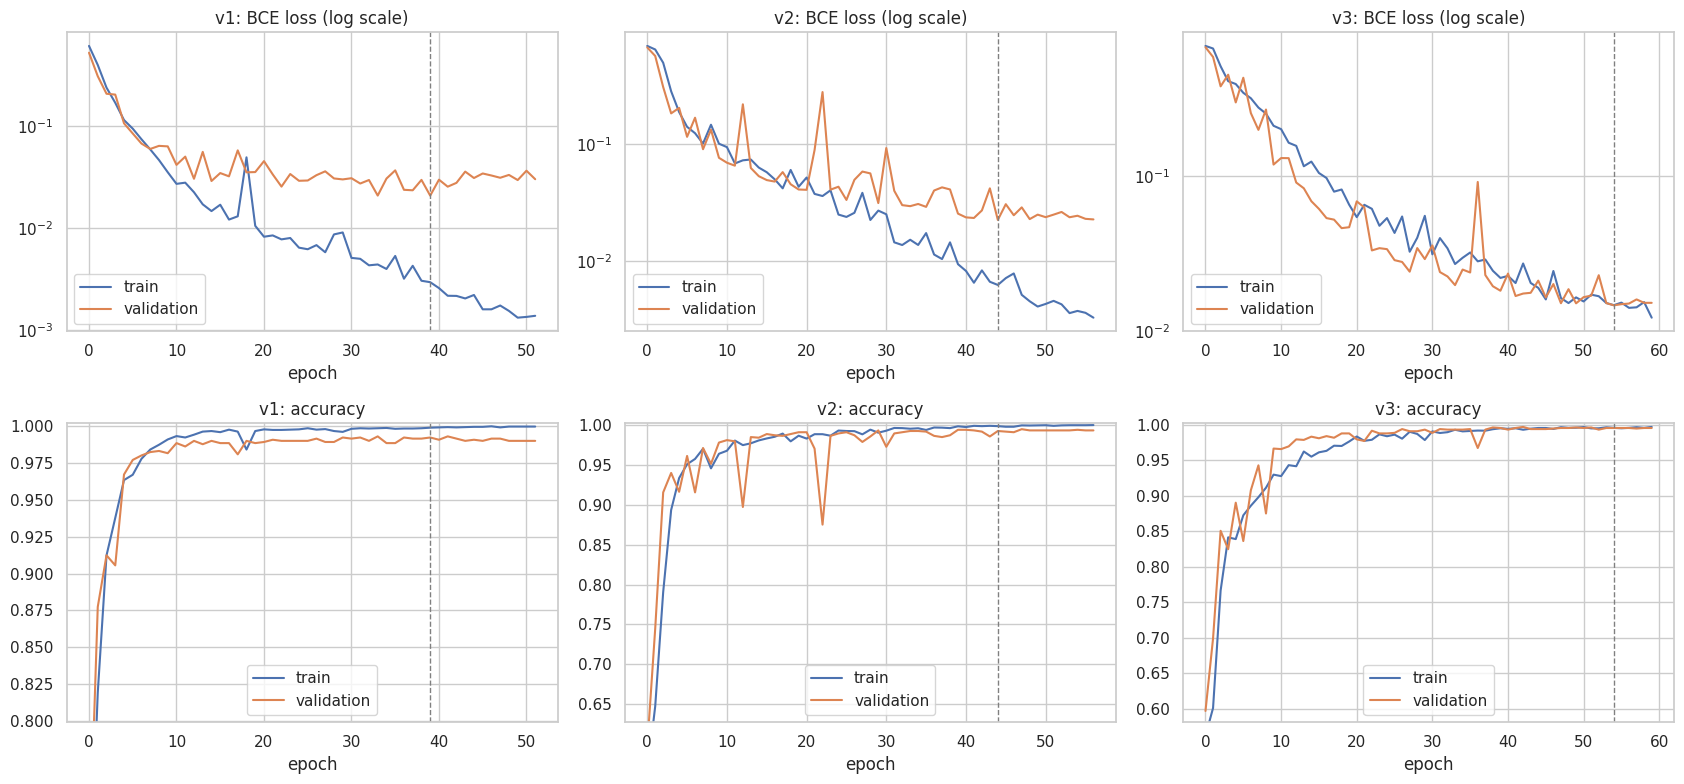

,parameters,epochs run,best epoch,train loss,val loss,train acc,val acc,fit time (s),gap (val − train loss)
v1,1848129.0,52.0,40.0,0.0030,0.0208,0.9990,0.9924,95.0728,0.0179
v2,240385.0,57.0,45.0,0.0062,0.0224,0.9985,0.9924,211.3248,0.0162
v3,240385.0,60.0,55.0,0.0147,0.0147,0.9956,0.9954,219.8147,-0.0000


In [ ]:
# Loss on a log scale: all versions reach very low loss, and on a linear axis the train/validation gap
# (the over/underfitting signal) is invisible. Each panel gets its own y-axis for the same reason.
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for j, v in enumerate(cnn):
    h = cnn[v]["history"]; best = int(np.argmin(h["val_loss"]))
    for i, (metric, title) in enumerate([("loss", "BCE loss (log scale)"), ("accuracy", "accuracy")]):
        ax = axes[i, j]
        ax.plot(h[metric], label="train"); ax.plot(h[f"val_{metric}"], label="validation")
        ax.axvline(best, ls="--", c="grey", lw=1)
        if metric == "loss":
            ax.set_yscale("log")
        else:
            ax.set_ylim(max(0.0, min(h["accuracy"][1:] + h["val_accuracy"][1:]) - 0.02), 1.002)
        ax.set_title(f"{v}: {title}"); ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout(); save_fig("B_cnn_learning_curves"); plt.show()

summary = {}
for v, r in cnn.items():
    h = r["history"]; best = int(np.argmin(h["val_loss"]))
    summary[v] = {"parameters": r["model"].count_params(), "epochs run": len(h["loss"]),
                  "best epoch": best + 1, "train loss": h["loss"][best], "val loss": h["val_loss"][best],
                  "train acc": h["accuracy"][best], "val acc": h["val_accuracy"][best],
                  "fit time (s)": r["fit_time"]}
iter_table = pd.DataFrame(summary).T
iter_table["gap (val − train loss)"] = iter_table["val loss"] - iter_table["train loss"]
iter_table = iter_table.astype(float).round(4)
iter_table.to_csv(f"{OUT_DIR}/B_iterations.csv")
iter_table

**Capacity and over/underfitting — how to read the curves**

Loss is plotted on a **log scale** so that the small train–validation gaps of nearly perfect models are visible. The side effect is that small absolute changes near zero (e.g. 0.02 → 0.04) look large, so judge wiggles by their size on the axis, not their visual height.

- **Overfitting** shows as training loss still falling while validation loss flattens or rises (a growing gap). Expect this most in **v1**, whose large dense head can memorise training images.
- **Underfitting** would show as *both* losses staying high. A model that is too shallow to see whole defects can show this pattern.
- **v3** trains on augmented images, so its training loss can sit *above* its validation loss early on — that is expected with dropout/augmentation (they are active only during training), not a bug.

The **final model is chosen on validation data only**, never on test results: lowest validation loss, with a parsimony tie-break (if several versions are within 10% of the best validation loss, the one with the fewest parameters wins).

**Design of the iteration.** The two steps change different things on purpose: v1 → v2 changes **capacity and architecture** (depth, filters, GAP instead of Flatten) with no regularisation, and v2 → v3 adds **regularisation only** on an identical backbone. So the v1/v2 comparison isolates the architecture effect and v2/v3 isolates the regularisation effect. Within v2 → v3, dropout and augmentation are introduced together, so their *individual* contributions are not separated. This is acknowledged as a limitation rather than claimed.

**Result.** All three versions exceed 99% validation accuracy, so at this resolution the task is close to saturated. The differences between versions show up mainly in the **loss and the train–validation gap**, which is why the loss is plotted on a log scale.

| | weights | best val loss | train–val gap | val acc | test errors (of 715) |
|---|---|---|---|---|---|
| v1 | 1,848,129 | 0.0208 | 0.0179 | 99.24% | 4 |
| v2 | 240,385 | 0.0224 | 0.0162 | 99.24% | 7 |
| v3 | 240,385 | **0.0147** | **0.0000** | **99.54%** | **1** |

- **v1 (1.85M weights): clear overfitting.** Its training loss keeps falling to ≈0.002, while validation loss flattens at ≈0.03 from epoch 20 onwards, the widest gap of the three. This is the Flatten → Dense head memorising training images, as predicted from its parameter count. Early stopping ended training at epoch 52 and restored epoch 40.
- **v2 (240k weights, 7.7× fewer):** same accuracy from far fewer weights, but still overfitting in this run. Replacing the Flatten → Dense head with global average pooling cut the weights 7.7×, yet v2 matches v1’s validation accuracy (99.24%) with a similar validation loss (0.0224 vs 0.0208). Its curves show the same pattern as v1: training loss keeps falling to ≈0.003 while validation loss levels off around 0.025 from epoch ≈40, with a few early spikes (epochs ≈12 and ≈22). So in this run the architecture change bought efficiency rather than less overfitting: its gap (0.0162) is only slightly smaller than v1’s (0.0179).
- **v3 (v2 + dropout + flip/transpose augmentation): the best version in this run.** Its training and validation curves stay on top of each other for the whole run, the gap at the best epoch is essentially zero, and it has both the lowest validation loss (0.0147) and the highest validation accuracy (99.54%). Regularisation did what it should: it closed the train–validation gap that v1 and v2 both show. (v3’s training loss is measured with dropout and augmentation active, so a zero gap means its training-mode and validation losses match, not that it cannot overfit at all.). Its training loss sits slightly above validation loss in early epochs because dropout and augmentation are only active during training. Getting v3 to work also needed two failed attempts, which are part of the iteration evidence:
  - *With batch normalisation* (first run), validation loss **spiked to ≈11** at several epochs (validation accuracy dropping to ≈0.4) while training loss stayed smooth (`figures/first_run_v3_batchnorm_unstable.png`). Batch norm normalises validation images with *moving averages* of past training batches. While the weights are still changing quickly, those averages describe a network that no longer exists. A controlled test on synthetic castings reproduced the failure, and faster-tracking averages (momentum 0.9) or a lower learning rate (3×10⁻⁴) each reduced but did not remove it, so batch norm was dropped. Set `V3_BATCHNORM = True` to reproduce it.
  - *With small random rotations* (±36°, `RandomRotation(0.1)`), v3 reached 99% training accuracy while validation accuracy swung between 0.70 and 0.93 from epoch to epoch. Every rotated image is *resampled*, which slightly blurs it, so v3 learned only from softened images and was then evaluated on sharp ones. Its edge- and texture-based defect detectors misfired on the sharper validation images. v2, with the identical backbone and recipe but no augmentation, was stable, which isolated the cause. Replacing rotation with **flips and transposes** (exact pixel rearrangements, no resampling, and valid because the castings are round and photographed from above) removed the problem entirely (`figures/v3_rotation_unstable.png` shows the rotation run).
- **Training recipe: two further iterations.** With the original recipe (Adam at 10⁻³, halved only when progress stalled, patience 8), every version showed late validation spikes, including v2, which has no batch norm (one epoch dropped to 0.69 accuracy). Late in training the model is nearly perfect, so a step that large can overshoot and make a handful of images confidently wrong.
  - *Attempt 1 (over-corrected):* a lower starting rate (3×10⁻⁴) with cosine decay and batch size 64. The curves became smooth, but only because the models barely learned: v2 and v3 stalled at ≈94.5% validation accuracy with training accuracy also ≈95%, which is underfitting.
  - *Attempt 2 (final):* the original starting rate (10⁻³) and batch size 32, plus a **cosine decay** to near zero over 60 epochs and patience 12. Large steps early let the models learn quickly, and the decay shrinks the step size in the late phase, exactly where the spikes occurred. The curves above show the result: most of the noise is in the first ≈40 epochs (v2 at epochs ≈12 and ≈22, v3 at ≈36), which is normal because each validation point is a single end-of-epoch snapshot while the training curve averages ≈165 batches, followed by a stable finish.
  - The lesson: smooth curves are not the goal in themselves. A smooth curve that plateaus with both training and validation scores low is underfitting.
- **No version underfits:** every version reaches over 99.5% training accuracy and over 99.2% validation accuracy.

**Selection.** By the pre-declared rule (lowest validation loss; anything within 10% counts as a tie and the smaller model wins), v3 is selected: v1’s loss is 41% higher and v2’s 52% higher, so neither counts as a tie. The parsimony tie-break was added after an earlier run in which v1 and v2 tied (0.0178 each); that is stated openly.

**The ranking moves between runs, and that is itself a finding.** This notebook was run four times on a GPU, and each time the networks trained slightly differently (GPU arithmetic is not bit-for-bit repeatable). v3 had a lower validation loss than v2 in three runs (0.0127 vs 0.0172, 0.0103 vs 0.0230, and 0.0147 vs 0.0224 in this run) and v2 in one (0.0121 vs 0.0135). v2 beat v1 in the earlier runs but not in this one (0.0224 vs 0.0208). The one result that held in every run is that v3 had the smallest train–validation gap. The honest conclusion is that dropout and augmentation reliably reduce overfitting here and usually, but not always, give the lowest validation loss; on this nearly saturated (and partly duplicated, B4) dataset the differences between versions are small. This run’s result is reported as it came out.

**Test check.** On the 715 test images v1, v2 and v3 make 4, 7 and 1 errors respectively (v1: 3 missed defects and 1 false alarm; v2: 7 missed defects; v3: 1 missed defect). The validation-selected model is also the best on test, though differences of a few images are within noise (limitation 8).

In [ ]:
# Selection on validation data only. Rule (parsimony): among versions whose best validation loss is within
# TOL of the best one, choose the one with the fewest parameters. Near-identical validation loss means the
# data cannot separate them, and the smaller model is cheaper, less prone to overfit and easier to deploy.
TOL = 0.10                                     # "within 10% of the best validation loss"
best_val = {v: min(r["history"]["val_loss"]) for v, r in cnn.items()}
contenders = [v for v in cnn if best_val[v] <= (1 + TOL) * min(best_val.values())]
FINAL = min(contenders, key=lambda v: (cnn[v]["model"].count_params(), best_val[v]))   # equal size → lower val loss
print("Best validation loss:", {v: round(l, 4) for v, l in best_val.items()})
print(f"Within {TOL:.0%} of the best: {contenders} → selected (fewest parameters): {FINAL}")

cnn_rows, cnn_prob = {}, {}
for v, r in cnn.items():
    cnn_prob[v] = r["model"].predict(X_img_test, verbose=0, batch_size=128).ravel()
    cnn_rows[v + (" (selected)" if v == FINAL else "")] = evaluate(y_img_test, cnn_prob[v], 0.5)
partB = pd.DataFrame(cnn_rows).T.round(4)
partB.to_csv(f"{OUT_DIR}/B_test_results.csv")
partB

Best validation loss: {'v1': 0.0208, 'v2': 0.0224, 'v3': 0.0147}
Within 10% of the best: ['v3'] → selected (fewest parameters): v3


,threshold,accuracy,balanced_acc,precision,recall,f1,roc_auc,pr_auc
v1,0.5,0.9944,0.9948,0.9978,0.9934,0.9956,0.9999,0.9999
v2,0.5,0.9902,0.9923,1.0000,0.9845,0.9922,0.9999,0.9999
v3 (selected),0.5,0.9986,0.9989,1.0000,0.9978,0.9989,1.0000,1.0000


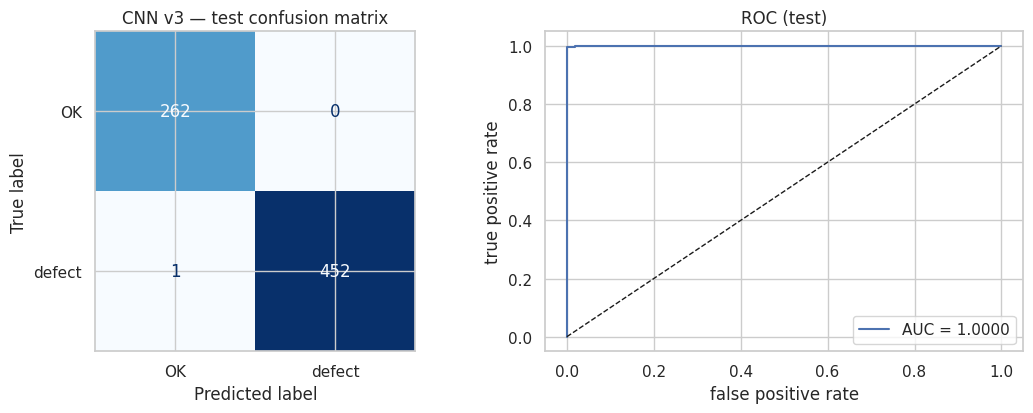

Inference: 0.38 ms per image


In [ ]:
final_model = cnn[FINAL]["model"]
p_final = cnn_prob[FINAL]
pred_final = (p_final >= 0.5).astype(int)

# Inference timing (after a warm-up call)
final_model.predict(X_img_test[:64], verbose=0)
t0 = time.perf_counter(); final_model.predict(X_img_test, verbose=0, batch_size=128)
cnn_ms_per_img = 1000 * (time.perf_counter() - t0) / len(X_img_test)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
ConfusionMatrixDisplay.from_predictions(y_img_test, pred_final, display_labels=["OK", "defect"],
                                        cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title(f"CNN {FINAL} — test confusion matrix")
fpr, tpr, _ = roc_curve(y_img_test, p_final)
axes[1].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_img_test, p_final):.4f}")
axes[1].plot([0, 1], [0, 1], "k--", lw=1); axes[1].legend()
axes[1].set(title="ROC (test)", xlabel="false positive rate", ylabel="true positive rate")
plt.tight_layout(); save_fig("B_cnn_test"); plt.show()
print(f"Inference: {cnn_ms_per_img:.2f} ms per image")

1 misclassified test images out of 715


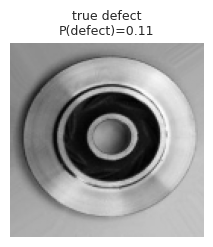

In [ ]:
wrong = np.where(pred_final != y_img_test)[0]
print(f"{len(wrong)} misclassified test images out of {len(y_img_test)}")
if len(wrong):
    n = min(len(wrong), 8)
    fig, axes = plt.subplots(1, n, figsize=(2.3 * n, 2.8), squeeze=False)
    for ax, i in zip(axes[0], wrong[:n]):
        ax.imshow(X_img_test[i, ..., 0], cmap="gray"); ax.axis("off")
        ax.set_title(f"true {'defect' if y_img_test[i] else 'OK'}\nP(defect)={p_final[i]:.2f}", fontsize=9)
    plt.tight_layout(); save_fig("B_misclassified"); plt.show()

## B3. Where does the CNN look? (Grad-CAM)

A CNN is not interpretable by default. **Grad-CAM** (Selvaraju et al., 2017) weights the last convolutional block's feature maps by the gradient of the defect score (the logit, i.e. the value before the sigmoid) with respect to them, giving a heatmap of the regions that pushed the prediction towards "defect". If the hot spots sit on the actual defects (holes, edge damage) rather than the background, the model has learned the right cues — useful evidence for an inspector to trust it.

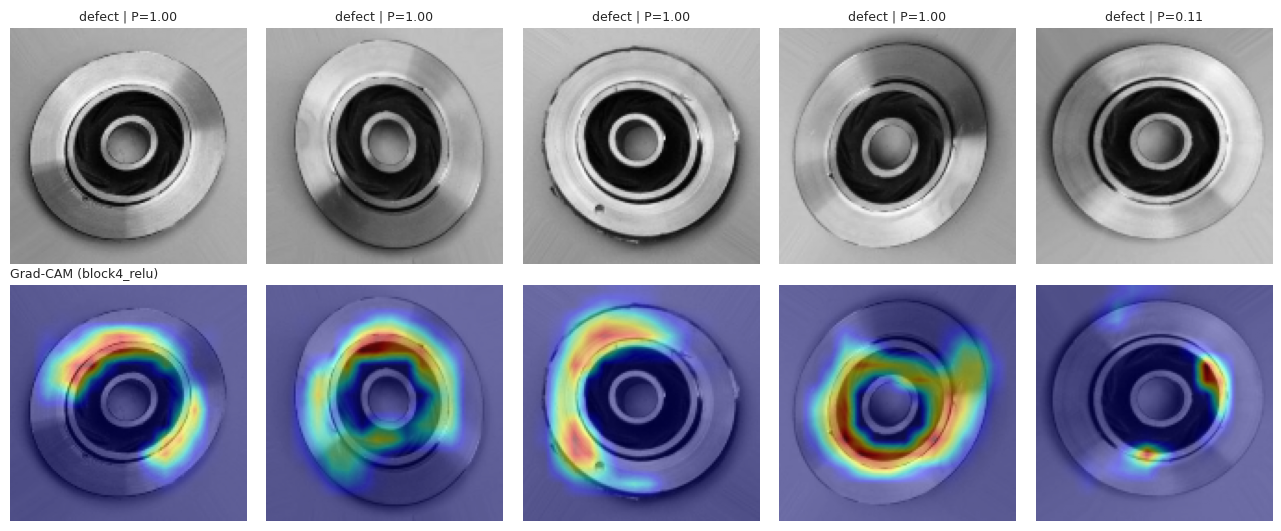

In [ ]:
def grad_cam(grad_model, image):
    # grad_model maps an image to (last conv feature maps, input to the output layer); built once below.
    # Gradients are taken of the LOGIT (the score before the sigmoid), as in Selvaraju et al. (2017).
    # Using P(defect) itself fails for confident predictions: at P ≈ 1.00 the sigmoid is flat, its gradient
    # is ~0 and the heatmap comes out blank.
    out_layer = final_model.get_layer("p_defect")
    with tf.GradientTape() as tape:
        fmap, penult = grad_model(image[None, ...], training=False)
        logit = tf.matmul(penult, out_layer.kernel) + out_layer.bias
        score = logit[:, 0]
    grads = tape.gradient(score, fmap)
    channel_w = tf.reduce_mean(grads, axis=(1, 2))                       # one weight per filter
    cam = tf.nn.relu(tf.reduce_sum(fmap * channel_w[:, None, None, :], axis=-1))[0]
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    return tf.image.resize(cam[..., None], (IMG_SIZE, IMG_SIZE)).numpy()[..., 0]

last_conv = [l.name for l in final_model.layers if l.name.endswith("_relu") or l.name == "conv2"][-1]
grad_model = keras.Model(final_model.inputs, [final_model.get_layer(last_conv).output,
                                              final_model.get_layer("p_defect").input])
show = list(np.where((y_img_test == 1) & (pred_final == 1))[0][:4]) + list(wrong[:2])
fig, axes = plt.subplots(2, len(show), figsize=(2.6 * len(show), 5.4), squeeze=False)
for j, i in enumerate(show):
    img = X_img_test[i, ..., 0]
    axes[0, j].imshow(img, cmap="gray"); axes[0, j].axis("off")
    axes[0, j].set_title(f"{'defect' if y_img_test[i] else 'OK'} | P={p_final[i]:.2f}", fontsize=9)
    axes[1, j].imshow(img, cmap="gray"); axes[1, j].imshow(grad_cam(grad_model, X_img_test[i]),
                                                           cmap="jet", alpha=0.45)
    axes[1, j].axis("off")
axes[1, 0].set_title(f"Grad-CAM ({last_conv})", loc="left", fontsize=9)
plt.tight_layout(); save_fig("B_gradcam"); plt.show()

## B4. Are the test photos really unseen? Near-duplicate check

The CNN's test results are almost perfect, which is a reason for suspicion rather than celebration. The B1 check removed training photos that are *byte-for-byte* copies of test photos, but the dataset's own description states that augmentation was already applied to the images. If rotated or flipped copies of the same physical part were created *before* the train/test split, the test set would contain parts the model has already studied, and a file-level check cannot see this.

**Method.** Each photo is shrunk to 64×64 and cropped to a circle (so rotation does not move the corners in and out of view). Each test photo is compared with every training photo under 120 orientations (every 6°, plain and mirrored), and the best match is kept. To know what similarity "different parts" reach, the same search is run against training photos of the **opposite class**: augmentation never changes a label, so an OK photo and a defective photo can never be the same part. A same-class match above the 99th percentile of these different-part similarities is treated as "same physical part".

Found 715 files belonging to 2 classes.
Compared 715 test photos x 120 orientations x 6569 training photos in 103s
Same-part threshold: 0.9919   (median same-class match 0.9955, median different-part match 0.9319)
OK        test photos with a same-part copy in training: 255 of 262 (97%)
defective test photos with a same-part copy in training: 342 of 453 (75%)


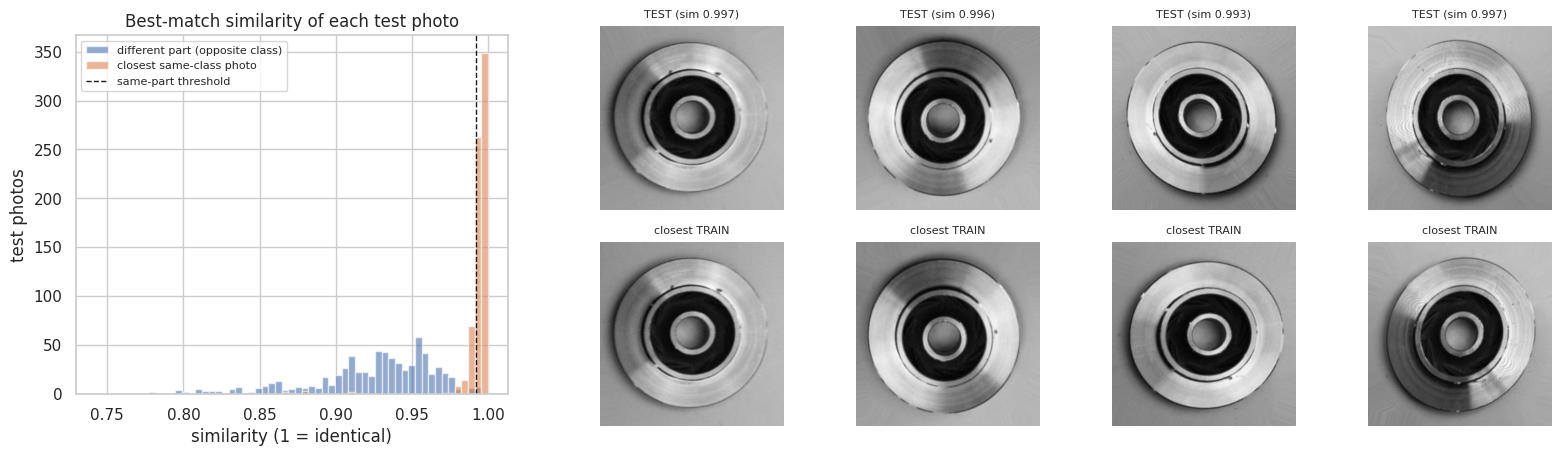

,photos,OK,defective,errors,accuracy,defects caught,false alarms
all test photos,715,262,453,1,0.9986,452/453,0
part also in training (copy),597,255,342,1,0.9983,341/342,0
part never seen in training,118,7,111,0,1.0000,111/111,0


In [ ]:
from PIL import Image
from scipy.ndimage import rotate as nd_rotate

SIM = 64
yy, xx = np.mgrid[:SIM, :SIM]
circle = ((yy - SIM / 2 + .5) ** 2 + (xx - SIM / 2 + .5) ** 2 < (SIM / 2 - 1) ** 2).ravel()   # rotation-safe crop

def load_small(paths):
    return np.stack([np.asarray(Image.open(p).convert("L").resize((SIM, SIM), Image.BILINEAR), np.float32) for p in paths])
def unit(X):
    X = X - X.mean(-1, keepdims=True)
    return X / (np.linalg.norm(X, axis=-1, keepdims=True) + 1e-8)

test_files  = keras.utils.image_dataset_from_directory(TEST_DIR, shuffle=False, **load_kw).file_paths  # same order as X_img_test
train_files = [os.path.join(CLEAN_TRAIN_DIR, c, f) for c in CLASS_NAMES
               for f in sorted(os.listdir(os.path.join(CLEAN_TRAIN_DIR, c)))]
train_lab = np.array([CLASS_NAMES.index(os.path.basename(os.path.dirname(f))) for f in train_files])
TRV = unit(load_small(train_files).reshape(len(train_files), -1)[:, circle])
TEI = load_small(test_files)

best_same = np.zeros(len(test_files)); best_opp = np.zeros(len(test_files)); match = np.zeros(len(test_files), int)
t0 = time.perf_counter()
for i, img in enumerate(TEI):
    views = [nd_rotate(im, a, reshape=False, order=1, mode="nearest").ravel()[circle]
             for im in (img, img[:, ::-1]) for a in range(0, 360, 6)]
    sims = (unit(np.array(views)) @ TRV.T).max(0)              # best orientation, for every training photo
    same = train_lab == y_img_test[i]
    best_same[i] = sims[same].max(); best_opp[i] = sims[~same].max()
    match[i] = np.where(same)[0][sims[same].argmax()]
print(f"Compared {len(test_files)} test photos x 120 orientations x {len(train_files)} training photos "
      f"in {time.perf_counter() - t0:.0f}s")

DUP_THR = np.percentile(best_opp, 99)            # 99th percentile of guaranteed-different-part similarity
has_copy = best_same > DUP_THR
print(f"Same-part threshold: {DUP_THR:.4f}   (median same-class match {np.median(best_same):.4f}, "
      f"median different-part match {np.median(best_opp):.4f})")

pred_v3 = (p_final >= 0.5).astype(int)
def subset(mask):
    y, q = y_img_test[mask], pred_v3[mask]
    return {"photos": int(mask.sum()), "OK": int((y == 0).sum()), "defective": int((y == 1).sum()),
            "errors": int((y != q).sum()), "accuracy": float((y == q).mean()),
            "defects caught": f"{int(((y == 1) & (q == 1)).sum())}/{int((y == 1).sum())}",
            "false alarms": int(((y == 0) & (q == 1)).sum())}
dup_table = pd.DataFrame({"all test photos": subset(np.ones(len(y_img_test), bool)),
                          "part also in training (copy)": subset(has_copy),
                          "part never seen in training": subset(~has_copy)}).T
dup_table["accuracy"] = dup_table["accuracy"].astype(float).round(4)
dup_table.to_csv(f"{OUT_DIR}/B_near_duplicates.csv")
for lab, name in [(0, "OK"), (1, "defective")]:
    m = y_img_test == lab
    print(f"{name:9s} test photos with a same-part copy in training: {has_copy[m].sum()} of {m.sum()} ({has_copy[m].mean():.0%})")

fig = plt.figure(figsize=(16, 4.6))
ax0 = fig.add_axes([0.04, 0.12, 0.27, 0.78])
bins = np.linspace(min(best_opp.min(), best_same.min()), 1, 60)
ax0.hist(best_opp, bins=bins, alpha=0.6, label="different part (opposite class)")
ax0.hist(best_same, bins=bins, alpha=0.6, label="closest same-class photo")
ax0.axvline(DUP_THR, c="k", ls="--", lw=1, label="same-part threshold")
ax0.set(title="Best-match similarity of each test photo", xlabel="similarity (1 = identical)", ylabel="test photos")
ax0.legend(fontsize=8)
rng_d = np.random.default_rng(SEED)
show = rng_d.choice(np.where(has_copy & (y_img_test == 1))[0], 4, replace=False)
for k, i in enumerate(show):
    for r, (path, ttl) in enumerate([(test_files[i], f"TEST (sim {best_same[i]:.3f})"), (train_files[match[i]], "closest TRAIN")]):
        ax = fig.add_axes([0.35 + k * 0.16, 0.52 - r * 0.47, 0.15, 0.4])
        ax.imshow(Image.open(path).convert("L"), cmap="gray"); ax.set_title(ttl, fontsize=8); ax.axis("off")
save_fig("B_near_duplicates"); plt.show()
dup_table

**Result: the test set is heavily contaminated by augmented copies.** The two distributions barely overlap. A test photo's closest same-class training photo has a median similarity of 0.996, while guaranteed-different parts reach a median of only 0.932. **597 of the 715 test photos (83%) have a rotated or flipped copy of the same physical part in the training set**: 97% of the OK photos and 75% of the defective ones. The randomly chosen pairs above show the same chips and marks in the same relative positions, just turned. The validation set, split randomly from the same pool, is affected in the same way.

**What this means for the CNN results:**

- The headline test accuracy (B2) is an **optimistic** estimate of performance on brand-new parts, because most test photos show parts the model trained on.
- The decisive check is the last row of the table: on the **118 test photos whose part never appears in training** (111 defective, 7 OK), the selected CNN (v3) still catches every one of the 111 defects. So it genuinely learned what defects look like, rather than memorising individual parts.
- Only 7 truly unseen OK photos remain, far too few to estimate the false-alarm rate on new good parts. That number is not known from this data.
- Comparisons *between* v1, v2 and v3 remain fair, because all three were trained and evaluated on the same contaminated split; it is the absolute level that is inflated.

**The proper fix** is a *group-aware* split that keeps every copy of a part on the same side (train or test). The dataset provides no part IDs, so this was not possible here beyond the approximation above. It is the first thing to change before relying on these numbers in a real deployment (C6). Finding this, rather than reporting 99.9% at face value, is part of the evaluation.

### Part B summary

**Final model: v3**, a four-block CNN (3×3 convolutions with 32 → 64 → 128 → 128 filters, each followed by 2×2 max-pooling), global average pooling, dropout 0.3 and one sigmoid output trained with binary cross-entropy, with flip and 90°-turn augmentation during training: 240,385 weights, 7.7× fewer than the v1 baseline. It was chosen on validation loss only (B2) and won clearly in this run (0.0147 vs 0.0208 for v1 and 0.0224 for v2); across four runs it had the lowest validation loss three times. On the 715 test images, v3 makes **one mistake**: 99.86% accuracy, precision 100% (no false alarms among 262 good parts) and recall 99.78% (452 of 453 defects caught).

The learning curves show **clear overfitting in v1** (training loss ≈0.002 vs validation ≈0.03), **similar overfitting in v2 in this run despite 7.7× fewer weights, no measurable gap in v3, where dropout and augmentation removed it**, and **no underfitting** in any version. The single error is a **confident miss**: a defective casting scored at only P(defect) = 0.11. Its defect is not visible at 128×128, which suggests the downsampling to 128×128 may hide some small defects, a reason to test the full 300×300 resolution. The ROC curve's AUC is 0.99996 (shown rounded as 1.0000): ranking is almost perfect, and the few good parts scored above this one defect are what keeps it from exactly 1.

**Important caveat (B4):** 83% of the test photos show a part that also appears, rotated or flipped, in the training set, so these test figures overstate performance on brand-new parts. On the 118 test photos of never-seen parts v3 caught all 111 defects, but the false-alarm rate on new good parts cannot be measured from this data.

**Grad-CAM** shows v3 concentrating on the casting itself, mainly the inner ring, the vane region and the rim, and not on the background. In some defective parts the hot spots coincide with visible damage (e.g. the chipped rim in the third example), while in others the heat is spread around the inner ring rather than pinpointing one defect. For the missed defect (last example) the heat is narrow and confined to one side, consistent with the model finding little evidence of a defect. The model is looking in the right *places*, but its explanations are approximate: useful to direct an inspector's eye, not as a precise defect locator. Grad-CAM works at the resolution of the last convolutional block (16×16 cells here), which limits how sharp the maps can be.

---
# Part C — Critical comparison and deployment recommendation

## C1. Side-by-side numbers

Important caveat: the CNN solves a **different task on different data** (visual defects on images) from the two tabular models (process failure from sensor readings). Its predictive scores therefore **cannot be ranked directly** against RF/MLP — a 99% CNN does not mean images are "better data" in general. The fair performance comparison is RF vs MLP; the CNN is compared on cost, data needs and interpretability, and on how well it does *its* job.

In [ ]:
def ms_per_sample(fn, X, reps=5):
    fn(X)                                     # warm-up
    t0 = time.perf_counter()
    for _ in range(reps):
        fn(X)
    return 1000 * (time.perf_counter() - t0) / (reps * len(X))

rf_ms  = ms_per_sample(lambda d: rf.predict_proba(d), Xte)
mlp_ms = ms_per_sample(mlp_prob, Xte)
hw = "GPU" if GPUS else "CPU"

m_rf  = evaluate(y_test, prob["Random Forest"]["test"], thr["Random Forest"])
m_mlp = evaluate(y_test, prob["MLP"]["test"], thr["MLP"])
m_cnn = evaluate(y_img_test, p_final, 0.5)

comparison = pd.DataFrame({
    "Random Forest": {"data": "AI4I sensors (tabular)", "training samples": len(y_train),
                      "input size": f"{Xtr.shape[1]} features",
                      "size": f"{sum(t.tree_.node_count for t in rf.estimators_):,} tree nodes",
                      "tuning / iteration time (s)": round(rf_search_time, 1),
                      "final fit time (s)": round(rf_fit_time, 2),
                      "inference (ms/sample)": round(rf_ms, 4), "hardware": "CPU", **m_rf},
    "MLP":           {"data": "AI4I sensors (tabular)", "training samples": len(y_train),
                      "input size": f"{Xtr.shape[1]} features",
                      "size": f"{mlp.count_params():,} weights",
                      "tuning / iteration time (s)": round(sum(r["fit_time"] for r in mlp_runs.values()), 1),
                      "final fit time (s)": round(mlp_fit_time, 2),
                      "inference (ms/sample)": round(mlp_ms, 4), "hardware": hw, **m_mlp},
    f"CNN ({FINAL})": {"data": "casting images", "training samples": n_img_train,
                      "input size": f"{IMG_SIZE}×{IMG_SIZE}×1 pixels",
                      "size": f"{final_model.count_params():,} weights",
                      "tuning / iteration time (s)": round(sum(r['fit_time'] for r in cnn.values()), 1),
                      "final fit time (s)": round(cnn[FINAL]["fit_time"], 1),
                      "inference (ms/sample)": round(cnn_ms_per_img, 4), "hardware": hw, **m_cnn},
})
for k in ["threshold", "accuracy", "balanced_acc", "precision", "recall", "f1", "roc_auc", "pr_auc"]:
    comparison.loc[k] = comparison.loc[k].astype(float).round(3)
comparison.to_csv(f"{OUT_DIR}/C_comparison.csv")
comparison

,Random Forest,MLP,CNN (v3)
data,AI4I sensors (tabular),AI4I sensors (tabular),casting images
training samples,6400,6400,5256
input size,11 features,11 features,128×128×1 pixels
size,"32,340 tree nodes",929 weights,"240,385 weights"
tuning / iteration time (s),263.9,403.0,526.2
final fit time (s),3.18,56.78,219.8
inference (ms/sample),0.042,0.0368,0.379
hardware,CPU,GPU,GPU
threshold,0.607,0.448,0.5
accuracy,0.991,0.98,0.999


## C2. Same data, all three models: why a CNN for images?

C1 cannot rank the CNN against RF/MLP because the tasks differ. To compare all three **on equal terms**, the Random Forest and an MLP are also trained on the casting images, as flattened raw pixels, using the same train/validation/test images as the CNN. Images are downsampled to 64×64 (4,096 inputs) to keep the RF and MLP tractable.

This tests the core claim of Lesson 5. A dense layer or a tree sees each pixel as an independent feature: it has no notion of neighbourhood, and a defect that moves a few pixels becomes a different input pattern. A CNN shares a small filter across every position, so the same defect is detected wherever it appears, with far fewer weights than a dense layer on the same pixels.

In [ ]:
SMALL = 64
def flatten_small(X):
    return tf.image.resize(X, (SMALL, SMALL)).numpy().reshape(len(X), -1) / 255.0

X_img_train, y_img_train = to_arrays(train_cached)
Xf_tr, Xf_va, Xf_te = flatten_small(X_img_train), flatten_small(X_img_val), flatten_small(X_img_test)
del X_img_train
print("Flattened pixel inputs:", Xf_tr.shape)

t0 = time.perf_counter()
rf_px = RandomForestClassifier(n_estimators=RF_N_TREES, max_features="sqrt", random_state=SEED, n_jobs=-1)
rf_px.fit(Xf_tr, y_img_train)
rf_px_time = time.perf_counter() - t0

mlp_px, _, mlp_px_time = train_mlp(Xf_tr, y_img_train, hidden=(128, 32), dropout=0.3,
                                   use_class_weight=False, X_v=Xf_va, y_v=y_img_val)

same_data = pd.DataFrame({
    "RF on pixels":  {"input": f"{SMALL}×{SMALL} flattened", "size": f"{sum(t.tree_.node_count for t in rf_px.estimators_):,} tree nodes",
                      "fit time (s)": round(rf_px_time, 1),
                      **evaluate(y_img_test, rf_px.predict_proba(Xf_te)[:, 1])},
    "MLP on pixels": {"input": f"{SMALL}×{SMALL} flattened", "size": f"{mlp_px.count_params():,} weights",
                      "fit time (s)": round(mlp_px_time, 1),
                      **evaluate(y_img_test, mlp_px.predict(Xf_te, verbose=0).ravel())},
    f"CNN ({FINAL})": {"input": f"{IMG_SIZE}×{IMG_SIZE} image", "size": f"{final_model.count_params():,} weights",
                      "fit time (s)": round(cnn[FINAL]["fit_time"], 1), **m_cnn},
}).T
same_data.to_csv(f"{OUT_DIR}/C_same_image_data.csv")
same_data[["input", "size", "fit time (s)", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]]

Flattened pixel inputs: (5256, 4096)


,input,size,fit time (s),accuracy,precision,recall,f1,roc_auc,pr_auc
RF on pixels,64×64 flattened,"118,450 tree nodes",121.0,0.967832,0.973568,0.975717,0.974642,0.995261,0.997217
MLP on pixels,64×64 flattened,"528,577 weights",59.7,0.836364,0.991228,0.748344,0.85283,0.953735,0.964394
CNN (v3),128×128 image,"240,385 weights",219.8,0.998601,1.0,0.997792,0.998895,0.999958,0.999976


**Result.** The Random Forest on raw pixels does surprisingly well: 96.8% accuracy, 97.6% recall. The photos are taken under very controlled lighting and pose, so even pixel-level brightness patterns separate many defects. It still makes **23 errors** on the 715 test images against the CNN's **1**, so 23× more mistakes, and on a line producing thousands of parts a day that difference is large. Its 118,450 tree nodes treat every pixel as an unrelated feature.

The MLP on pixels is far worse: 83.6% accuracy and **117 errors**, and it misses a quarter of the defects (recall 74.8%), despite 528,577 weights. Its first dense layer alone holds 4,096 × 128 = 524,288 weights, more than **twice the entire CNN** (240,385). A dense layer learns a separate weight for every pixel position, so a blow-hole seen at one position teaches it nothing about the same blow-hole elsewhere. A convolutional layer slides one shared 3×3 filter over every position, so it detects the same defect anywhere in the image with a tiny fraction of the weights. This comparison is the clearest evidence in the notebook that the CNN is the right model for the image task, and it holds when all three models see exactly the same images.


===== CNN v3 on 1314 training images (25%) =====
Epoch 1/60
42/42 - 13s - 304ms/step - accuracy: 0.5586 - auc: 0.4824 - loss: 0.6919 - precision: 0.5699 - recall: 0.9034 - val_accuracy: 0.5971 - val_auc: 0.3810 - val_loss: 0.6816 - val_precision: 0.5971 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 2/60
42/42 - 1s - 26ms/step - accuracy: 0.5670 - auc: 0.4935 - loss: 0.6854 - precision: 0.5670 - recall: 1.0000 - val_accuracy: 0.5971 - val_auc: 0.5933 - val_loss: 0.6742 - val_precision: 0.5971 - val_recall: 1.0000 - learning_rate: 9.9931e-04
Epoch 3/60
42/42 - 1s - 26ms/step - accuracy: 0.5677 - auc: 0.5294 - loss: 0.6828 - precision: 0.5674 - recall: 1.0000 - val_accuracy: 0.5971 - val_auc: 0.5972 - val_loss: 0.6702 - val_precision: 0.5971 - val_recall: 1.0000 - learning_rate: 9.9726e-04
Epoch 4/60
42/42 - 1s - 26ms/step - accuracy: 0.5670 - auc: 0.5471 - loss: 0.6813 - precision: 0.5670 - recall: 1.0000 - val_accuracy: 0.5971 - val_auc: 0.6532 - val_loss: 0.6660 - val_precision: 

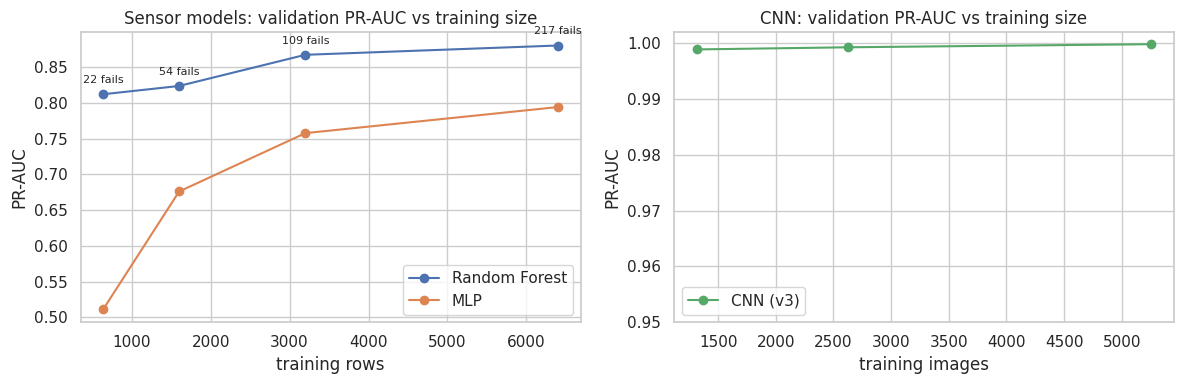

,fraction,training rows,failures in training,RF val PR-AUC,MLP val PR-AUC
0,0.10,640,22,0.812,0.511
1,0.25,1600,54,0.824,0.676
2,0.50,3200,109,0.867,0.758
3,1.00,6400,217,0.880,0.794


,fraction,training images,CNN val PR-AUC
0,0.25,1314,0.999
1,0.50,2628,0.999
2,1.00,5256,1.000


In [ ]:
tab_rows = []
for f in [0.10, 0.25, 0.50, 1.00]:
    if f < 1:
        Xs, _, ys, _ = train_test_split(X_train, y_train, train_size=f, stratify=y_train, random_state=SEED)
    else:
        Xs, ys = X_train, y_train
    pre_f = make_preprocessor(FEATURES).fit(Xs[FEATURES + CAT])
    Xs_t, Xv_t = pre_f.transform(Xs[FEATURES + CAT]), pre_f.transform(X_val[FEATURES + CAT])
    rf_f = RandomForestClassifier(n_estimators=RF_N_TREES, random_state=SEED, n_jobs=-1, **grid.best_params_).fit(Xs_t, ys)
    mlp_f, _, _ = train_mlp(Xs_t, ys, X_v=Xv_t, y_v=y_val, **MLP_CFG)
    tab_rows.append({"fraction": f, "training rows": len(ys), "failures in training": int(ys.sum()),
                     "RF val PR-AUC": average_precision_score(y_val, rf_f.predict_proba(Xv_t)[:, 1]),
                     "MLP val PR-AUC": average_precision_score(y_val, mlp_f.predict(Xv_t, verbose=0).ravel())})
tab_curve = pd.DataFrame(tab_rows)

cnn_rows = []
if RUN_CNN_DATA_SIZE:
    for f in [0.25, 0.50]:
        k = int(f * n_img_train)
        subset = (train_cached.unbatch().take(k).batch(BATCH_SIZE).cache()
                  .shuffle(1000, seed=SEED).prefetch(AUTOTUNE))
        print(f"\n===== CNN {FINAL} on {k} training images ({f:.0%}) =====")
        r = train_cnn(FINAL, subset, tag=f"frac{f}")
        cnn_rows.append({"fraction": f, "training images": k, "CNN val PR-AUC":
                         average_precision_score(y_img_val, r["model"].predict(X_img_val, verbose=0).ravel())})
cnn_rows.append({"fraction": 1.0, "training images": n_img_train, "CNN val PR-AUC":
                 average_precision_score(y_img_val, final_model.predict(X_img_val, verbose=0).ravel())})
cnn_curve = pd.DataFrame(cnn_rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(tab_curve["training rows"], tab_curve["RF val PR-AUC"], "o-", label="Random Forest")
axes[0].plot(tab_curve["training rows"], tab_curve["MLP val PR-AUC"], "o-", label="MLP")
for _, r in tab_curve.iterrows():
    axes[0].annotate(f"{int(r['failures in training'])} fails", (r["training rows"], r["RF val PR-AUC"]),
                     textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
axes[0].set(title="Sensor models: validation PR-AUC vs training size", xlabel="training rows", ylabel="PR-AUC")
axes[0].legend()
axes[1].plot(cnn_curve["training images"], cnn_curve["CNN val PR-AUC"], "o-", c="C2", label=f"CNN ({FINAL})")
axes[1].set(title="CNN: validation PR-AUC vs training size", xlabel="training images", ylabel="PR-AUC")
axes[1].set_ylim(min(0.95, cnn_curve["CNN val PR-AUC"].min() - 0.01), 1.002)   # full-scale axis: tiny differences stay tiny
axes[1].legend()
plt.tight_layout(); save_fig("C_data_size_curves"); plt.show()

tab_curve.to_csv(f"{OUT_DIR}/C_data_size_tabular.csv"); cnn_curve.to_csv(f"{OUT_DIR}/C_data_size_cnn.csv")
display(tab_curve.round(3)); display(cnn_curve.round(3))

**Result.** **The Random Forest is far more data-efficient.** With only 10% of the training rows (640 rows, just **22 failures**) it already reaches validation PR-AUC 0.812, which is 92% of its full-data score (0.880). The MLP collapses when failures are scarce: 0.511 at 10%, only 64% of its full-data score (0.794). The gap between them narrows from 0.30 at 10% to 0.09 at 100%. Neural networks need many examples of the rare class to shape a decision boundary by gradient descent, whereas a tree can isolate a cluster of failures with a few splits. Both curves are **still rising** at 100% (50% → 100% adds +0.013 for the RF and +0.036 for the MLP), so more labelled failures would help both, and the MLP most.

**The CNN curve is essentially flat**: validation PR-AUC 0.999 with 25% of the images (1,314), 0.999 with 50%, and 1.000 with all 5,256 (final architecture, v3). A quarter of the images, still far above 300 per class, is already enough. On this dataset image quantity is not the bottleneck, because the photos are consistent and the defects visually distinct. Part of the flatness is also the near-duplicate effect (B4): even a quarter of the training photos contains rotated copies of most validation parts, so the curve says little about how much data truly *new* parts would need. That would likely change under varied lighting, cameras or product types (C6).

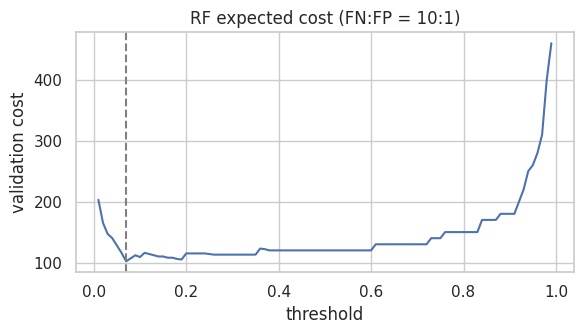

,threshold,failures caught,failures missed,false alarms,test cost
F1-optimal threshold,0.61,52.0,16.0,2.0,162.0
cost-optimal threshold,0.07,60.0,8.0,57.0,137.0


In [ ]:
COST_FN, COST_FP = 10, 1
grid_t = np.linspace(0.01, 0.99, 99)
def expected_cost(y_true, p, t):
    pred = p >= t
    return COST_FN * np.sum((y_true == 1) & ~pred) + COST_FP * np.sum((y_true == 0) & pred)

p_val, p_te = prob["Random Forest"]["val"], prob["Random Forest"]["test"]
val_costs = [expected_cost(y_val.values, p_val, t) for t in grid_t]
t_cost = float(grid_t[int(np.argmin(val_costs))])

rows = {}
for label, t in [("F1-optimal threshold", thr["Random Forest"]), ("cost-optimal threshold", t_cost)]:
    tn, fp, fn, tp = confusion_matrix(y_test, (p_te >= t).astype(int)).ravel()
    rows[label] = {"threshold": round(t, 2), "failures caught": tp, "failures missed": fn,
                   "false alarms": fp, "test cost": COST_FN * fn + COST_FP * fp}
plt.figure(figsize=(6, 3.5))
plt.plot(grid_t, val_costs); plt.axvline(t_cost, ls="--", c="grey")
plt.xlabel("threshold"); plt.ylabel("validation cost"); plt.title(f"RF expected cost (FN:FP = {COST_FN}:{COST_FP})")
plt.tight_layout(); save_fig("C_cost_threshold"); plt.show()
pd.DataFrame(rows).T

**Result.** Making missed failures 10× as costly as false alarms moves the RF's best threshold from 0.61 (F1-optimal) down to **0.07**. On the test set the model then catches **60 of 68** failures instead of 52 (8 missed instead of 16), at the price of 57 false alarms instead of 2. Total cost falls from 162 to 137 units (−15%). The *model* is unchanged; only the operating point moves. This is why the threshold should come from the plant's real cost ratio rather than a default of 0.5 or an F1 optimum, and why PR-AUC (threshold-free) was used to choose between models.

## C5. Discussion

**Interpretability.** The Random Forest is the most useful to a plant engineer. Its permutation importance is led by rotational speed, the air–process temperature gap and strain (tool wear × torque), all variables an operator can act on: slow the spindle, improve cooling, change the tool. Individual trees can be inspected, though the 300-tree forest as a whole is a grey box. The MLP's 929 weights have no physical meaning and could only be explained after the fact with a model-agnostic tool (permutation importance). Reassuringly, it relies on the same physical drivers, leaning most on raw torque and speed. The CNN is a black box by construction, but Grad-CAM gives *local* explanations: it shows that the model attends to the casting (inner ring, vanes, rim) rather than the background, and sometimes highlights the damage itself. These maps are approximate (16×16 resolution), so they can direct an inspector's eye but cannot certify *where* a defect is.

**Data requirements.** The RF needs the least: no scaling or class weighting, and 92% of its full performance from only 22 training failures (C3). The MLP needs standardised inputs, careful tuning (5 variants, A5) and many failures. It drops to 0.51 PR-AUC with 22 failures, and its test score varies 15× more than the RF's between random seeds (A6). The CNN needs thousands of labelled images and benefits from augmentation, although here a quarter of the dataset already sufficed (C3). Labelling images costs inspector time, and less controlled imaging would raise the requirement. Data *quality* matters too: 64 training images were exact copies of test images and had to be removed (B1), and most test photos turned out to be rotated copies of training parts (B4). A dataset of this kind needs part IDs so it can be split by part rather than by photo. C2 shows that the type of model matters as much as the amount of data: on the same images, models without spatial structure need far more weights for far worse results.

**Computational and training cost** (Colab: CPU for the RF, T4 GPU for the networks). One final RF fit takes ≈3 s, its grid search ≈4–5 min, and the trained forest holds 32,340 tree nodes. The MLP's final fit takes ≈1 min and its 5-variant iteration ≈7 min. Most of that is per-epoch overhead (up to 300 epochs) rather than computation, since the model has only 929 weights. The CNN is the most expensive: ≈3.7 min for the final v3 and ≈9 min for all three versions on the GPU. On CPU the same CNN training takes over an hour (≈36–38 min per version in a separate CPU run), so a GPU is effectively required for iterating on CNNs. Inference is cheap for all three: ≈0.04 ms per sample for the RF and the MLP, and ≈0.4 ms per image for the CNN. That is thousands of predictions per second, so inference cost does not limit any choice.

**Predictive performance.** On the sensor data the RF wins clearly and reliably: test PR-AUC 0.902 vs 0.768, a bootstrap CI for the difference that excludes zero, and a lead that holds across 5 seeds. In practice it catches 52 of 68 failures with 2 false alarms, against the MLP's 37 with 8. Its advantage is concentrated in heat-dissipation failures, an AND-type rule that suits trees. Neither model can predict tool-wear failures, which occur at random. The CNN solves its own task almost perfectly (1 error in 715 test images and no false alarms). That figure is optimistic, because 83% of the test photos show parts that also appear, rotated, in training (B4). On the photos of never-seen parts it still catches the defects, so the conclusion stands, but its real-world false-alarm rate is unknown, and C2 shows it beats both the RF (23 errors) and an MLP (117 errors) when all three are given the same images. Its scores cannot be ranked against the sensor models because the data and the question differ (C1).

**Recommendation for SmartFactory.** The two data sources answer different questions at different points on the line, so the recommendation is to **deploy two models, not pick one**:

1. **Random Forest on the sensor stream as an early-warning layer during production.** It is the most accurate and stable sensor model, cheap (CPU-only, milliseconds) and explainable in plant terms. Its threshold should be set from the plant's real costs rather than F1. With an assumed 10:1 cost ratio, lowering the threshold to 0.07 catches 60 of 68 failures instead of 52, at the price of 57 false alarms instead of 2, and cuts total cost by 15% (C4).
2. **CNN (v3) as the final visual-inspection gate on finished parts**, after re-validating it on photos of genuinely new parts (B4) to measure its false-alarm rate. Low-confidence predictions go to a human inspector together with the Grad-CAM heatmap. A review band (e.g. P(defect) between 0.25 and 0.75) catches uncertain cases, but this run's single error was a *confident* miss (P = 0.11) that such a band would not catch. That is why the miss rate on genuinely new parts must be measured before relying on the CNN alone, possibly at full 300×300 resolution.

The MLP is **not recommended**. It is less accurate, catches fewer failures with more false alarms, is less stable, needs more data and is harder to explain than the RF, so it adds complexity without benefit. For deployment, both models should be monitored for drift (new tools, materials, lighting), retrained periodically, and kept under a human-in-the-loop review for flagged units.

## C6. Limitations

Stating these shows the conclusions are held with the right level of confidence:

1. **Synthetic sensor data.** AI4I's labels come from documented rules, which favours threshold-learning models and likely overstates real-world performance. Results should be re-validated on real plant data before deployment.
2. **Proxy label.** AI4I predicts *machine* failure during production, used here as a proxy for a unit failing QC (A1). The two are related but not identical.
3. **Two unlinked datasets.** The sensor rows and casting images describe different products, so the two pipelines could not be evaluated *together* on the same units (e.g. does combining them catch more defects?). A real deployment would need unit IDs linking sensor logs to photos.
4. **One test split, few positives.** The sensor test set has only ~68 failures, so small differences are within noise (see the bootstrap CIs and seed spread).
5. **Near-duplicate photos (most important for Part B).** 83% of test photos have a rotated or flipped copy of the same part in training (B4), so the CNN's test accuracy is optimistic. Defect detection holds on never-seen parts, but only 7 never-seen OK photos exist, so the false-alarm rate on new parts is unmeasured. The proper fix is a split by part, which needs part IDs the dataset does not provide.
6. **Controlled imaging.** The casting photos are taken under consistent lighting and pose; performance under different cameras or lighting is untested.
7. **Partially separated CNN changes.** In v2 → v3, dropout and augmentation were added together, so their separate effects are unknown. Batch normalisation and small-angle rotation were tried and dropped for instability, so their potential benefits were not realised. Across four GPU runs the v2-versus-v3 ranking flipped (v3 won three times, v2 once), and in this run v2 did not beat v1, so the effect of each change on validation loss is within run-to-run noise; only regularisation’s effect on the train–validation gap was consistent.
8. **Test set noise on the image task.** With the CNNs at 1–7 errors out of 715, the differences between versions on the *test* set are a handful of images. The validation loss (B2) is the more reliable basis for comparing them, which is why it was used for selection.
9. **Assumed costs.** The 10:1 cost ratio in C4 is illustrative; the plant must supply real costs.

## Report map (how this notebook supports the 1,200–1,600 word report)

| Report section | Suggested words | Evidence in this notebook | Rubric criterion it serves |
|---|---|---|---|
| Introduction: problem, datasets, positive class, metric choice | ~150 | A1, A2, B1 | 1 (selection & justification) |
| Part A: RF and MLP, why each, tuning/iteration, results | ~450 | A4 screen, grid search, RF validation curve; A5 MLP variants; A6 test table, bootstrap CIs, recall by failure mode; A7 importances | 1, 2, 3 |
| Part B: CNN design, iteration, loss, over/underfitting | ~400 | B2 architecture table, iteration table, learning curves; test results; Grad-CAM; B4 near-duplicate check | 2, 3 |
| Part C: comparison on the four required axes + recommendation | ~450 | C1 table, C2 same-data check, C3 data-size curves, C4 cost threshold, C5, C6 | 3 |
| Conclusion | ~100 | — | 4 |

**Figures worth putting in the report** (from `outputs/`): `A_test_comparison`, `A_rf_validation_curve`, `A_mlp_learning_curves`, `B_cnn_learning_curves`, `B_gradcam`, `B_near_duplicates`, `C_data_size_curves`. Tables: `C_comparison` and `C_same_image_data` (trim to the key rows). Tables and figures don't count towards the word limit, so let them carry the numbers and spend words on interpretation.

**Before submitting:** push the notebook, `outputs/` (the `models/` subfolder is optional, ≈33 MB), `figures/`, `README.md` and `requirements.txt` to GitHub. If you re-run the notebook, check that the numbers quoted in the commentary still match the outputs.

## Reproducibility

All randomness is seeded (`SEED = 42`). The saved outputs in this copy come from one complete run on Google Colab with a **T4 GPU**, with the data downloaded from UCI and Kaggle (the cells check the row/image counts match the originals). A separate full run on a CPU-only machine gave identical Random Forest results, and neural-network results that differ slightly in the last decimal places and in the epoch at which early stopping stops, because floating-point arithmetic is not bit-identical across hardware. The main conclusions (RF over MLP, a CNN for the images, and the two-model deployment) were the same in both runs; only the choice between the closely matched CNN v2 and v3 varies from run to run (B2). All figures and tables are saved in `outputs/`; trained CNNs are cached in `outputs/models`.

In [ ]:
import sklearn, platform
print("Python", platform.python_version(), "| TF", tf.__version__, "| scikit-learn", sklearn.__version__,
      "| pandas", pd.__version__, "| numpy", np.__version__)
print("Saved outputs:", sorted(os.listdir(OUT_DIR)))

Python 3.13.15 | TF 2.21.0 | scikit-learn 1.6.1 | pandas 2.2.3 | numpy 2.1.3
Saved outputs: ['A_bootstrap_ci.csv', 'A_classical_screen.csv', 'A_eda_boxplots.png', 'A_feature_ablation.csv', 'A_feature_importance.png', 'A_mlp_iterations.csv', 'A_mlp_learning_curves.png', 'A_recall_by_failure_mode.csv', 'A_rf_capacity.csv', 'A_rf_validation_curve.png', 'A_seed_stability.csv', 'A_seed_stability.png', 'A_test_comparison.png', 'A_test_results.csv', 'B_cnn_learning_curves.png', 'B_cnn_test.png', 'B_gradcam.png', 'B_iterations.csv', 'B_misclassified.png', 'B_near_duplicates.csv', 'B_near_duplicates.png', 'B_sample_images.png', 'B_test_results.csv', 'C_comparison.csv', 'C_cost_threshold.png', 'C_data_size_cnn.csv', 'C_data_size_curves.png', 'C_data_size_tabular.csv', 'C_same_image_data.csv', 'models']


## References

- Breiman, L. (2001) 'Random forests', *Machine Learning*, 45(1), pp. 5–32. doi:10.1023/A:1010933404324.
- Ioffe, S. and Szegedy, C. (2015) 'Batch normalization: accelerating deep network training by reducing internal covariate shift', *Proceedings of the 32nd International Conference on Machine Learning*, PMLR 37, pp. 448–456.
- Lin, M., Chen, Q. and Yan, S. (2014) 'Network in network', *International Conference on Learning Representations (ICLR)*. Available at: https://arxiv.org/abs/1312.4400
- Loshchilov, I. and Hutter, F. (2017) 'SGDR: stochastic gradient descent with warm restarts', *International Conference on Learning Representations (ICLR)*. Available at: https://openreview.net/forum?id=Skq89Scxx
- Matzka, S. (2020a) 'Explainable artificial intelligence for predictive maintenance applications', *2020 Third International Conference on Artificial Intelligence for Industries (AI4I)*. Irvine, CA: IEEE, pp. 69–74.
- Matzka, S. (2020b) *AI4I 2020 predictive maintenance dataset*. UCI Machine Learning Repository. doi:10.24432/C5HS5C.
- ravirajsinh45 (2020) *Casting product image data for quality inspection*. Kaggle. Available at: https://www.kaggle.com/datasets/ravirajsinh45/real-life-industrial-dataset-of-casting-product (Accessed: 20 October 2026).
- Selvaraju, R.R., Cogswell, M., Das, A., Vedantam, R., Parikh, D. and Batra, D. (2017) 'Grad-CAM: visual explanations from deep networks via gradient-based localization', *Proceedings of the IEEE International Conference on Computer Vision (ICCV)*, pp. 618–626. doi:10.1109/ICCV.2017.74.